# Assignment · Representaciones de lenguaje: BoW y Word2Vec

**Sesión 1 · Asignment**
**Clase: Modelos de Lenguaje de Gran Escala**
**Universidad de La Sabana**
**Autor: Andres Rosso**  
**Estudiante: Alejandro Moncada**

¿Cómo se pasa de contar palabras sueltas a capturar algo parecido al significado? Al contar, cada palabra ocupa su propia dimensión en un espacio ortogonal y disperso, donde `police` y `officers` no tienen ninguna relación. Los embeddings las llevan a un espacio latente denso y continuo, donde sí pueden quedar cerca.
En este notebook sigo ese viaje con noticias de la BBC y miro dónde falla cada paso, porque ahí se entiende por qué hicieron falta los modelos que sostienen a los LLM.

## Resumen

**Objetivo:** construir sobre `BBC news.csv` las herramientas vistas en clase (tokenizador, frecuencias, Zipf, Bag of Words, concordancias y Word2Vec) y comparar qué captura cada representación.

**Dataset:** 1.000 noticias de la BBC, con el texto en la columna `content`. Son 522.750 tokens y 25.616 palabras distintas; 918 noticias son de 2021 a 2024 y no hay columna de categoría.

**Contenido:**

- [0. Preparación](#s0)
- [1. Tokenización y preparación del corpus](#s1)
- [2. Frecuencias, bigramas y Zipf](#s2)
- [3. Bag of Words, TF-IDF y el límite de BoW](#s3)
- [4. Concordancias y contexto](#s4)
- [5. Word2Vec](#s5)
- [6. Integración, análisis crítico y puente hacia Transformers](#s6)
- [Resumen de representaciones](#resumen-rep)
- [Conclusión](#conclusion)

## <a id="s0"></a>0. Preparación

Cargo las librerías y dejo `BBC news.csv` en un `DataFrame` llamado `df`.

In [1]:
import random
import re
import time
import zlib
from collections import Counter
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from adjustText import adjust_text
from gensim.models import Word2Vec
from matplotlib.patches import Rectangle
from matplotlib.patheffects import withStroke
from matplotlib.ticker import FuncFormatter
from scipy import sparse
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfTransformer
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GRAY = "#b5b3ac"
GRIS_NEUTRO, ACENTO = "#c9c7c0", "#123f7a"
INK, MUTED, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"

sns.set_theme(style="whitegrid", rc={
    "figure.dpi": 120,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": "#d8d6cf",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlelocation": "left",
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelcolor": MUTED,
    "grid.color": "#ecebe6",
    "text.color": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "legend.frameon": False,
})


def es(valor, decimales=0):
    texto = f"{valor:,.{decimales}f}"
    return texto.translate(str.maketrans(",.", ".,"))


def titular(ax, titulo, subtitulo):
    ax.set_title(titulo, pad=26)
    ax.text(0, 1.03, subtitulo, transform=ax.transAxes, color=MUTED, fontsize=9.5)


def ticks_es(eje, decimales=0):
    eje.set_major_formatter(FuncFormatter(lambda valor, _: es(valor, decimales)))


def nota(ax, texto, xy, xytext, **kwargs):
    ax.annotate(
        texto, xy=xy, xytext=xytext, fontsize=9, color=INK,
        arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8), **kwargs,
    )


RUTA_CSV = "BBC news.csv"

df = pd.read_csv(RUTA_CSV)

display(df.head())
print(df.shape)

,id,url,author,headline,topics,publication_date,content,videos,images,related_articles,keyword
0,65219434,https://www.bbc.com/news/uk-65219434,By Lauren Turner,"Junior doctors' strike could hit up to 250,000...","[""Doctors"",""NHS"",""British Medical Association ...","""2023-04-08T09:32:35.000Z""",Up to quarter of a million operations and appo...,[],"[{""image_description"":""Main image"",""image_url""...","[{""article_title"":""Axing new GP surgery a 'nig...",NaN
1,67657828,https://www.bbc.com/news/uk-scotland-67657828,BBC,Musical postbox spreading Christmas cheer in G...,"[""Glasgow""]","""2023-12-10T09:07:32.000Z""",A musical postbox is spreading Christmas cheer...,"[{""video_description"":""The musical postbox pla...",[],"[{""article_title"":""'My family will never get o...",NaN
2,c8vvdz8lr7ro,https://www.bbc.com/news/articles/c8vvdz8lr7ro,Dan Martin,'Show off' teen BMW driver crashed into car me...,"[""Sutton in Ashfield"",""Annesley"",""M1 motorway""]","""2024-06-27T10:51:11.116Z""",A teenager has been sentenced for dangerous dr...,[],"[{""image_description"":""Main image"",""image_url""...","[{""article_title"":""Salon robbery suspect arres...",NaN
3,61303221,https://www.bbc.com/news/business-61303221,Peter Hoskins,UK MPs invite Musk to be quizzed on Twitter plans,"[""Social media"",""Mergers and acquisitions"",""El...","""2022-05-04T16:13:26.000Z""",UK MPs have invited Elon Musk to parliament so...,"[{""video_description"":""Who is Elon Musk? Meet ...","[{""image_description"":""Main image"",""image_url""...","[{""article_title"":""TikTok sued for 'wreaking h...",NaN
4,cedx9xz9dv4o,https://www.bbc.com/news/articles/cedx9xz9dv4o,BBC,Six charged with attempted murder in car theft...,"[""Edinburgh""]","""2024-04-22T15:28:32.056Z""",Six men have been charged with attempted murde...,[],"[{""image_description"":""Main image"",""image_url""...","[{""article_title"":""Netflix bid to fit One Day ...",NaN


(1000, 11)


### EDA del corpus

Antes de tokenizar reviso qué trae el archivo y si hay algo que afecte las decisiones de la sección 1.

**Hipótesis:** esperaba un archivo limpio, con noticias de longitud parecida.

In [2]:
texts = df["content"]
years = df["publication_date"].str.strip('"').str[:4]
chars = texts.str.len()

display(pd.DataFrame({
    "Comprobación": [
        "Nulos en content",
        "Noticias con content duplicado",
        "URLs duplicadas",
        "Nulos en keyword",
        "Noticias con menos de 500 caracteres",
        "Separadores ';' en el texto",
        "Separadores ';' justo después de punto",
        "Apóstrofes tipográficos (’)",
    ],
    "Valor": [
        texts.isna().sum(),
        texts.duplicated().sum(),
        df["url"].duplicated().sum(),
        df["keyword"].isna().sum(),
        (chars < 500).sum(),
        texts.str.count(";").sum(),
        texts.str.count(r"\.;").sum(),
        texts.str.count("’").sum(),
    ],
}))
display(chars.describe().round(0).to_frame("Caracteres por noticia"))
display(years.value_counts().sort_index().to_frame("Noticias").T)

top_10_docs_share = chars.sort_values().tail(10).sum() / chars.sum()
print(f"Las 10 noticias más largas concentran {top_10_docs_share:.1%} de los caracteres.")
print("Secciones más comunes en la URL:")
sections = df["url"].str.extract(r"bbc\.com/([a-z]+/[a-z]+)")[0]
print(sections.value_counts().head(5).to_dict())

,Comprobación,Valor
0,Nulos en content,0
1,Noticias con content duplicado,0
2,URLs duplicadas,0
3,Nulos en keyword,977
4,Noticias con menos de 500 caracteres,29
5,Separadores ';' en el texto,15017
6,Separadores ';' justo después de punto,12679
7,Apóstrofes tipográficos (’),1939


,Caracteres por noticia
count,1000.0
mean,3119.0
std,3493.0
min,194.0
25%,1051.0
50%,2114.0
75%,3762.0
max,57732.0


publication_date,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
Noticias,1,3,1,7,13,8,9,7,6,6,21,179,231,271,237


Las 10 noticias más largas concentran 7.7% de los caracteres.
Secciones más comunes en la URL:
{'news/uk': 456, 'news/articles': 191, 'news/business': 110, 'news/world': 65, 'news/technology': 43}


**Hallazgo:** está limpio, pero las longitudes no se parecen.

- Trabajo con `content`, la única columna con el cuerpo de la noticia. No tiene nulos ni duplicados, así que se quedan las 1.000 noticias.
- Las longitudes son muy dispares: la mediana es 2.114 caracteres y la más larga llega a 57.732. Solo 10 noticias concentran el 7,7 % del texto.
- El corpus es reciente y desbalanceado en el tiempo: 918 noticias son de 2021 a 2024.
- No hay columna de categoría. `keyword` está vacía en 977 filas, así que no comparo por categorías.
- El archivo une párrafos con `; `: de 15.017 punto y comas, 12.679 vienen justo después de un punto. Por eso los trato como fin de oración.

## <a id="s1"></a>1. Tokenización y preparación del corpus · 20%

Escribo el tokenizador a mano, sin librerías externas. Paso todo a minúsculas, conservo las contracciones del inglés y dejo como opción si se quedan los números. También separo cada noticia en oraciones y creo las columnas `oraciones`, `tokens` y `longitud`.

In [3]:
STOP = set(ENGLISH_STOP_WORDS)

SENTENCE_SPLIT = re.compile(r"(?<=[.!?])\s+|;\s+")


def tokenizar(texto, minusculas=True, numeros=False):
    if minusculas:
        texto = texto.lower()
    chars = "a-z" if minusculas else "a-zA-Z"
    if numeros:
        chars += "0-9"
    return re.findall(rf"[{chars}]+(?:'[{chars}]+)*", texto)


def oraciones_tokenizadas(texto):
    oraciones = (tokenizar(o) for o in SENTENCE_SPLIT.split(texto))
    return [o for o in oraciones if o]


df["oraciones"] = df["content"].map(oraciones_tokenizadas)
df["tokens"] = df["content"].map(tokenizar)
df["longitud"] = df["tokens"].map(len)

FRECUENCIAS = Counter(t for tokens in df["tokens"] for t in tokens)

assert df["oraciones"].map(lambda o: sum(map(len, o))).equals(df["longitud"])

### Comprobación

Antes de seguir reviso el tamaño del corpus: cuántas noticias, tokens y palabras distintas tiene, y cuáles son las 10 palabras más frecuentes sin *stop words*.

**Hipótesis:** con las decisiones de tokenización de la clase debería llegar a unos 523.000 tokens y 25.600 palabras distintas.

In [4]:
n_noticias = len(df)
n_tokens = int(df["longitud"].sum())
n_palabras = len(FRECUENCIAS)
top_10 = [(w, f) for w, f in FRECUENCIAS.most_common() if w not in STOP][:10]

print("1. Noticias:", n_noticias)
print("2. Tokens:", n_tokens)
print("3. Palabras distintas:", n_palabras)
print("4. Top 10 sin stop words:", top_10)

1. Noticias: 1000
2. Tokens: 522750
3. Palabras distintas: 25616
4. Top 10 sin stop words: [('said', 3771), ('mr', 1802), ('people', 1375), ('bbc', 1370), ('s', 1370), ('says', 1169), ('year', 1166), ('police', 1155), ('car', 1121), ('twitter', 991)]


,Referencia de clase,Obtenido,Diferencia %
Noticias,1000,1000,0.00
Tokens,523000,522750,-0.05
Palabras distintas,25600,25616,0.06


,Variante,Tokens,Palabras distintas,Δ tokens,Δ palabras
0,"Elegida: minúsculas, sin números, contracciones",522750,25616,0,0
1,Conservando números,531248,26873,8498,1257
2,Sin pasar a minúsculas,522750,28901,0,3285
3,Normalizando ’ a ',521019,25755,-1731,139
4,Sin contracciones,527805,24777,5055,-839


Las stop words son 47.7% de los tokens y se conservan en el corpus.
Ejemplo del apóstrofe tipográfico: ['don', 't', 'and', "don't"]
Frecuencia de los fragmentos 's' y 't': 1370 345


,Tokens por noticia
count,1000.0
mean,523.0
std,579.0
min,35.0
25%,178.0
50%,354.0
75%,630.0
max,9323.0


Oraciones en el corpus: 23731


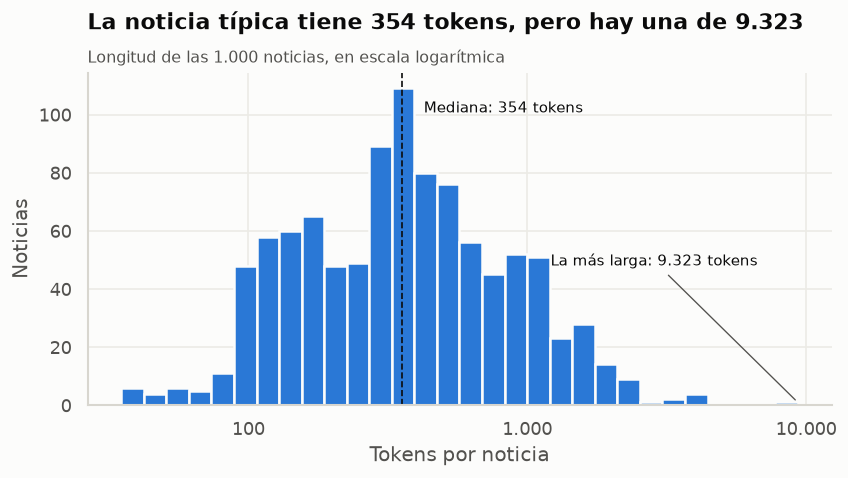

In [5]:
REFERENCIA = {"Noticias": 1000, "Tokens": 523000, "Palabras distintas": 25600}
obtenido = {"Noticias": n_noticias, "Tokens": n_tokens, "Palabras distintas": n_palabras}

verificacion = pd.DataFrame({"Referencia de clase": REFERENCIA, "Obtenido": obtenido})
verificacion["Diferencia %"] = (
    (verificacion["Obtenido"] / verificacion["Referencia de clase"] - 1) * 100
).round(2)
display(verificacion)
assert (verificacion["Diferencia %"].abs() <= 1).all()


def measure(name, tokenize):
    counts = Counter(t for text in df["content"] for t in tokenize(text))
    return {"Variante": name, "Tokens": sum(counts.values()), "Palabras distintas": len(counts)}


variantes = pd.DataFrame([
    measure("Elegida: minúsculas, sin números, contracciones", tokenizar),
    measure("Conservando números", lambda t: tokenizar(t, numeros=True)),
    measure("Sin pasar a minúsculas", lambda t: tokenizar(t, minusculas=False)),
    measure("Normalizando ’ a '", lambda t: tokenizar(t.replace("’", "'"))),
    measure("Sin contracciones", lambda t: re.findall(r"[a-z]+", t.lower())),
])
variantes["Δ tokens"] = variantes["Tokens"] - n_tokens
variantes["Δ palabras"] = variantes["Palabras distintas"] - n_palabras
display(variantes)

stop_tokens = sum(f for w, f in FRECUENCIAS.items() if w in STOP)
print(f"Las stop words son {stop_tokens / n_tokens:.1%} de los tokens y se conservan en el corpus.")
print("Ejemplo del apóstrofe tipográfico:", tokenizar("don’t and don't"))
print("Frecuencia de los fragmentos 's' y 't':", FRECUENCIAS["s"], FRECUENCIAS["t"])

display(df["longitud"].describe().round(0).to_frame("Tokens por noticia"))
print("Oraciones en el corpus:", int(df["oraciones"].map(len).sum()))

mediana = df["longitud"].median()
maximo = df["longitud"].max()
fig, ax = plt.subplots(figsize=(8, 3.6))
sns.histplot(df, x="longitud", log_scale=True, bins=30, color=BLUE, edgecolor=SURFACE, linewidth=1.5, alpha=1, ax=ax)
ax.axvline(mediana, color=INK, lw=1, ls="--")
ax.text(mediana * 1.2, ax.get_ylim()[1] * 0.88, f"Mediana: {es(mediana)} tokens", fontsize=9)
nota(ax, f"La más larga: {es(maximo)} tokens", (maximo, 1), (maximo * 0.13, ax.get_ylim()[1] * 0.42))
titular(ax, f"La noticia típica tiene {es(mediana)} tokens, pero hay una de {es(maximo)}", "Longitud de las 1.000 noticias, en escala logarítmica")
ax.set(xlabel="Tokens por noticia", ylabel="Noticias")
ticks_es(ax.xaxis)
plt.show()

**Hallazgo y decisiones de preprocesamiento.** Los conteos coinciden con la referencia de clase (−0,05 % en tokens y +0,06 % en vocabulario), y la tabla de variantes muestra cuánto pesa cada decisión:

- **Minúsculas:** no cambian los tokens, pero sin ellas el vocabulario sube en 3.285 palabras porque `The` y `the` contarían aparte.
- **Números:** fuera por defecto. Incluirlos suma 8.498 tokens y 1.257 palabras, y el análisis no se apoya en cifras. Se pueden activar con `numeros=True`.
- **Contracciones:** se conservan como un solo token (`don't`), como pide el enunciado. Separarlas sumaría 5.055 tokens.
- **Apóstrofe tipográfico:** no lo normalizo, porque así se reproducen los conteos de clase. Tiene un costo visible: `don’t` se parte en `don` y `t`, y el fragmento `s` aparece 1.370 veces, tanto que entra al top 10. Normalizarlo restaría 1.731 tokens y sumaría 139 palabras, también dentro del 1 %.
- **Stop words:** son el 47,7 % de los tokens, pero se quedan en el corpus porque las concordancias y Word2Vec necesitan la oración completa. Solo se ocultan en tablas de frecuencias, bigramas y BoW.
- **Límites del tokenizador:** solo reconoce letras de la `a` a la `z`, así que una palabra con tilde se corta, y una abreviatura con punto parte la oración.

Todas las secciones usan estos mismos documentos y estas mismas columnas.

## <a id="s2"></a>2. Frecuencias, bigramas y Zipf · 20%

`explorar_frecuencias` me deja ver las palabras o los bigramas más frecuentes, con o sin *stop words*, y devuelve un `DataFrame` ordenado por frecuencia.

In [6]:
BIGRAMAS = Counter(
    bigrama
    for oraciones in df["oraciones"]
    for oracion in oraciones
    for bigrama in zip(oracion, oracion[1:])
)


def explorar_frecuencias(n=10, ocultar_stopwords=True, unidad="Palabras"):
    if unidad == "Palabras":
        items = FRECUENCIAS.items()
        keep = lambda w: w not in STOP
        show = str
    elif unidad == "Bigramas":
        items = BIGRAMAS.items()
        keep = lambda b: b[0] not in STOP and b[1] not in STOP
        show = " ".join
    else:
        raise ValueError("unidad debe ser 'Palabras' o 'Bigramas'")
    filas = [(show(k), f) for k, f in items if not ocultar_stopwords or keep(k)]
    filas.sort(key=lambda fila: (-fila[1], fila[0]))
    return pd.DataFrame(filas[:n], columns=[unidad[:-1], "Frecuencia"])


display(explorar_frecuencias(10, True, "Palabras"))
display(explorar_frecuencias(10, True, "Bigramas"))

,Palabra,Frecuencia
0,said,3771
1,mr,1802
2,people,1375
3,bbc,1370
4,s,1370
5,says,1169
6,year,1166
7,police,1155
8,car,1121
9,twitter,991


,Bigrama,Frecuencia
0,mr musk,508
1,year old,441
2,follow bbc,361
3,story ideas,355
4,police said,328
5,junior doctors,216
6,social media,215
7,elon musk,185
8,facebook twitter,169
9,dangerous driving,155


In [7]:
display(explorar_frecuencias(10, False, "Palabras"))
display(explorar_frecuencias(10, False, "Bigramas"))

,Palabra,Frecuencia
0,the,28565
1,to,15136
2,a,13591
3,and,13142
4,of,12779
5,in,10905
6,on,5730
7,that,5110
8,for,5004
9,was,4712


,Bigrama,Frecuencia
0,of the,2625
1,in the,2532
2,to the,1353
3,on the,1107
4,in a,1039
5,at the,1037
6,to be,884
7,for the,744
8,and the,664
9,has been,650


**Hipótesis:** sin stop words, las palabras más frecuentes deberían mostrar los temas del corpus, y los bigramas deberían confirmarlos.

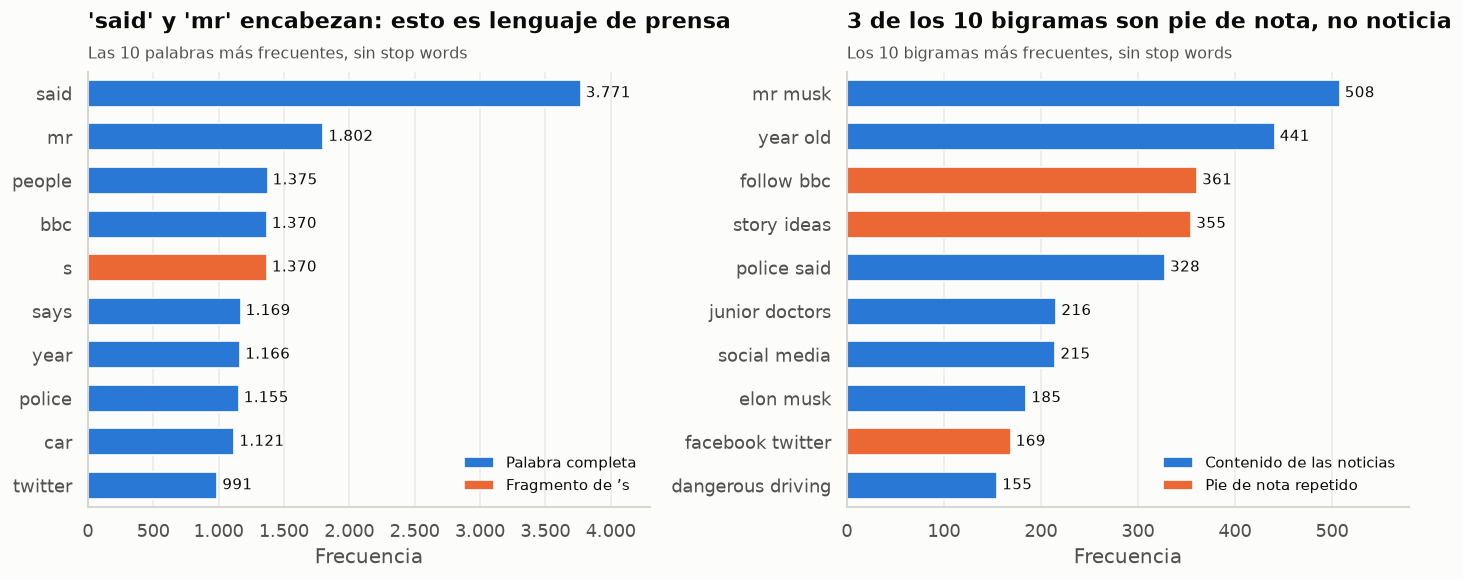

In [8]:
PIE_DE_NOTA = {"follow bbc", "story ideas", "facebook twitter"}

palabras_top = explorar_frecuencias(10, True, "Palabras")
palabras_top["Tipo"] = np.where(palabras_top["Palabra"] == "s", "Fragmento de ’s", "Palabra completa")
bigramas_top = explorar_frecuencias(10, True, "Bigramas")
bigramas_top["Tipo"] = np.where(bigramas_top["Bigrama"].isin(PIE_DE_NOTA), "Pie de nota repetido", "Contenido de las noticias")
n_pie = int(bigramas_top["Bigrama"].isin(PIE_DE_NOTA).sum())

fig, (izq, der) = plt.subplots(1, 2, figsize=(12, 5))
paneles = [
    (izq, palabras_top, "Palabra", {"Palabra completa": BLUE, "Fragmento de ’s": ORANGE},
     f"'{palabras_top.iloc[0, 0]}' y '{palabras_top.iloc[1, 0]}' encabezan: esto es lenguaje de prensa", "Las 10 palabras más frecuentes, sin stop words"),
    (der, bigramas_top, "Bigrama", {"Contenido de las noticias": BLUE, "Pie de nota repetido": ORANGE},
     f"{n_pie} de los 10 bigramas son pie de nota, no noticia", "Los 10 bigramas más frecuentes, sin stop words"),
]
for ax, datos, columna, colores, titulo, subtitulo in paneles:
    sns.barplot(datos, y=columna, x="Frecuencia", hue="Tipo", palette=colores, dodge=False, width=0.62, saturation=1, ax=ax)
    for pos, valor in enumerate(datos["Frecuencia"]):
        ax.text(valor, pos, f" {es(valor)}", va="center", fontsize=9)
    ax.set(xlabel="Frecuencia", ylabel=None)
    ax.margins(x=0.14)
    ax.grid(axis="y", visible=False)
    ticks_es(ax.xaxis)
    titular(ax, titulo, subtitulo)
    ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

**Hallazgo:** las palabras sueltas no muestran tanto los temas como el estilo de prensa (`said`, `mr`); los temas aparecen más en los bigramas. Con stop words, la tabla es casi pura gramática (`of the`, `in the`). Sin ellas se ve de qué habla el corpus: `mr musk` (508), `junior doctors` (216), `dangerous driving` (155).

También se ve cómo está hecho el archivo: `follow bbc` (361), `story ideas` (355) y `facebook twitter` (169) vienen del texto repetido al final de las notas, no de la noticia. No lo quito porque cambiaría los conteos de referencia, pero conviene tenerlo presente al leer las frecuencias.

### Zipf

Ahora miro si el corpus sigue la ley de Zipf. `graficar_zipf` ordena las frecuencias de mayor a menor y las grafica contra su rango, con los dos ejes en escala logarítmica.

**Hipótesis:** los puntos deberían formar una recta con pendiente cercana a −1.

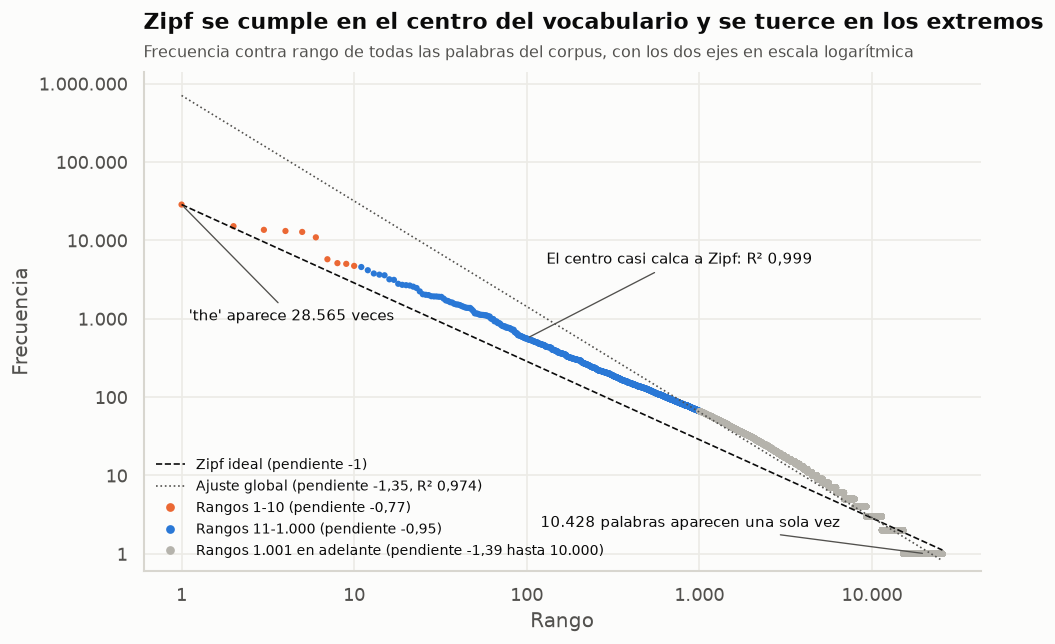

In [9]:
def fit_zipf(freqs, start, end):
    ranks = np.arange(start, end + 1)
    x, y = np.log10(ranks), np.log10(freqs[start - 1:end])
    slope, intercept = np.polyfit(x, y, 1)
    r2 = 1 - ((y - (slope * x + intercept)) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    return slope, intercept, r2


def graficar_zipf():
    freqs = np.array(sorted(FRECUENCIAS.values(), reverse=True))
    ranks = np.arange(1, len(freqs) + 1)
    slope, intercept, r2 = fit_zipf(freqs, 1, len(freqs))
    centro, _, r2_centro = fit_zipf(freqs, 11, 1000)
    cabeza, _, _ = fit_zipf(freqs, 1, 10)
    final, _, _ = fit_zipf(freqs, 1001, 10000)
    tramos = {
        f"Rangos 1-10 (pendiente {es(cabeza, 2)})": ORANGE,
        f"Rangos 11-1.000 (pendiente {es(centro, 2)})": BLUE,
        f"Rangos 1.001 en adelante (pendiente {es(final, 2)} hasta 10.000)": GRAY,
    }
    nombres = list(tramos)
    datos = pd.DataFrame({
        "Rango": ranks,
        "Frecuencia": freqs,
        "Tramo": np.select([ranks <= 10, ranks <= 1000], nombres[:2], nombres[2]),
    })

    fig, ax = plt.subplots(figsize=(9, 5.4))
    ax.plot(ranks, freqs[0] / ranks, "--", color=INK, lw=1, label="Zipf ideal (pendiente -1)")
    ax.plot(ranks, 10 ** intercept * ranks ** slope, ":", color=MUTED, lw=1, label=f"Ajuste global (pendiente {es(slope, 2)}, R² {es(r2, 3)})")
    sns.scatterplot(datos, x="Rango", y="Frecuencia", hue="Tramo", palette=tramos, s=14, linewidth=0, ax=ax)
    ax.set(xscale="log", yscale="log", xlabel="Rango", ylabel="Frecuencia", ylim=(0.6, None))

    primera = FRECUENCIAS.most_common(1)[0][0]
    hapax = (freqs == 1).sum()
    nota(ax, f"'{primera}' aparece {es(freqs[0])} veces", (1, freqs[0]), (1.1, freqs[0] / 30))
    nota(ax, f"El centro casi calca a Zipf: R² {es(r2_centro, 3)}", (100, freqs[99]), (130, freqs[99] * 9))
    nota(ax, f"{es(hapax)} palabras aparecen una sola vez", (ranks[-1] * 0.8, 1), (120, 2.2))
    titular(ax, "Zipf se cumple en el centro del vocabulario y se tuerce en los extremos", "Frecuencia contra rango de todas las palabras del corpus, con los dos ejes en escala logarítmica")
    ax.legend(loc="lower left", fontsize=8.5, markerscale=1.4)
    ticks_es(ax.xaxis)
    ticks_es(ax.yaxis)
    plt.show()


graficar_zipf()

In [10]:
freqs = np.array(sorted(FRECUENCIAS.values(), reverse=True))
tramos = [(1, 10), (11, 1000), (1001, 10000), (10001, len(freqs)), (1, len(freqs))]
filas = []
for start, end in tramos:
    slope, _, r2 = fit_zipf(freqs, start, end)
    filas.append({
        "Rango": f"{start}-{end}",
        "Pendiente": round(slope, 2),
        "R²": round(r2, 3),
        "% de tokens": round(freqs[start - 1:end].sum() / n_tokens * 100, 1),
    })
display(pd.DataFrame(filas))

hapax = (freqs == 1).sum()
print(f"Palabras con frecuencia 1: {hapax} ({hapax / len(freqs):.1%} del vocabulario, {hapax / n_tokens:.2%} de los tokens)")
print("Frecuencia × rango en los primeros rangos:", [(r, int(freqs[r - 1] * r)) for r in (1, 2, 5, 10, 100, 1000, 10000)])

,Rango,Pendiente,R²,% de tokens
0,1-10,-0.77,0.871,21.9
1,11-1000,-0.95,0.999,50.8
2,1001-10000,-1.39,0.993,23.0
3,10001-25616,-1.29,0.762,4.2
4,1-25616,-1.35,0.974,100.0


Palabras con frecuencia 1: 10428 (40.7% del vocabulario, 1.99% de los tokens)
Frecuencia × rango en los primeros rangos: [(1, 28565), (2, 30272), (5, 63895), (10, 47120), (100, 56000), (1000, 66000), (10000, 30000)]


**Hallazgo: ¿se cumple Zipf?** Sí, aproximadamente, y sobre todo en el centro de la distribución. Entre los rangos 11 y 1.000 la pendiente es −0,95 con R² de 0,999, muy cerca del −1 esperado, y ese tramo reúne el 50,8 % de los tokens.

En los extremos se desvía. Las 10 palabras más frecuentes caen más suave (−0,77) y ya suman el 21,9 % de los tokens. Desde el rango 1.001 la caída es más rápida (−1,39 y −1,29). Por eso el ajuste global da −1,35 aunque su R² sea 0,974: una sola recta esconde esa curvatura. Frecuencia × rango tampoco es constante: en los rangos revisados se mueve entre 28.565 y 66.000.

La cola se ve en escalones porque muchas palabras empatan: 10.428 aparecen una sola vez, el 40,7 % del vocabulario pero apenas el 1,99 % de los tokens.

## <a id="s3"></a>3. Bag of Words · 20%

`construir_bow` arma la matriz documento-término de los primeros `n_documentos`. Le indico el tamaño máximo del vocabulario y si quito las *stop words*.

In [11]:
def bow_from_tokens(documentos, max_palabras=None, eliminar_stopwords=False):
    conteos = [Counter(t for t in doc if not eliminar_stopwords or t not in STOP) for doc in documentos]
    total = sum(conteos, Counter())
    vocabulario = [w for w, _ in sorted(total.items(), key=lambda kv: (-kv[1], kv[0]))][:max_palabras]
    return pd.DataFrame(
        [[c[w] for w in vocabulario] for c in conteos],
        columns=vocabulario,
        index=[f"Doc {i}" for i in range(len(documentos))],
    )


def construir_bow(n_documentos=5, max_palabras=15, eliminar_stopwords=True):
    documentos = df["tokens"].iloc[:n_documentos].tolist()
    return bow_from_tokens(documentos, max_palabras, eliminar_stopwords)


bow = construir_bow()
display(bow)

,said,musk,mr,twitter,bbc,car,strike,speech,committee,health,junior,protect,social,uk,users
Doc 0,9,0,1,0,5,0,8,0,1,6,6,3,1,2,0
Doc 1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Doc 2,6,0,0,0,2,6,0,0,0,0,0,0,3,1,0
Doc 3,8,13,11,11,1,0,0,7,5,0,0,3,2,3,6
Doc 4,2,0,0,0,0,2,0,0,0,0,0,0,0,0,0


### Prueba de la representación

Para ver qué pasa con el orden, comparo dos frases con las mismas palabras y sentido contrario:

`The student corrects the teacher`

`The teacher corrects the student`

**Hipótesis:** como solo cuenta palabras, BoW debería darles el mismo vector.

In [12]:
frases = [
    "The student corrects the teacher",
    "The teacher corrects the student"
]

tokens_frases = [tokenizar(f) for f in frases]
bow_frases = bow_from_tokens(tokens_frases)
bow_frases.index = frases
display(bow_frases)

iguales = bow_frases.iloc[0].equals(bow_frases.iloc[1])
print("¿Los dos vectores BoW son iguales?", iguales)
assert iguales

bigramas_frases = [set(zip(t, t[1:])) for t in tokens_frases]
print("¿Los bigramas son iguales?", bigramas_frases[0] == bigramas_frases[1])
print("Bigramas que solo están en la primera frase:", sorted(bigramas_frases[0] - bigramas_frases[1]))

noticia = df["tokens"].iloc[0]
barajada = random.Random(SEED).sample(noticia, len(noticia))
print("Noticia 0 original:", " ".join(noticia[:10]), "...")
print("Noticia 0 barajada:", " ".join(barajada[:10]), "...")
print("¿Mismo vector BoW con las palabras barajadas?", Counter(noticia) == Counter(barajada))

,the,corrects,student,teacher
The student corrects the teacher,2,1,1,1
The teacher corrects the student,2,1,1,1


¿Los dos vectores BoW son iguales? True
¿Los bigramas son iguales? False
Bigramas que solo están en la primera frase: [('student', 'corrects')]
Noticia 0 original: up to quarter of a million operations and appointments could ...
Noticia 0 barajada: will likely four consultants massive are and emailing safe the ...
¿Mismo vector BoW con las palabras barajadas? True


BoW conserva qué palabras aparecen en cada documento y cuántas veces.  
Pierde el orden y, con él, quién hace qué: las dos frases dan el mismo vector aunque digan lo contrario, y la noticia 0 barajada también.  
Los bigramas recuperan algo de eso: `student corrects` solo está en la primera frase.

### TF-IDF

**Hipótesis:** TF-IDF debería bajar las palabras repartidas por todo el corpus y subir las que se concentran en algunas noticias. Calculo la matriz con mi propio tokenizador; de scikit-learn solo uso el paso de conteos a TF-IDF.

Matriz BoW: 1000 × 25616, esparsidad 99.02%
Suben gracias a TF-IDF: ['bmw', 'crash', 'died', 'driving', 'man', 'road']
Salen del top 15: ['like', 'new', 'people', 'says', 'time', 'uk']
Mediana de tokens: todas 354, con 'crash' 181 (264 noticias), con 'musk' 529 (123 noticias)


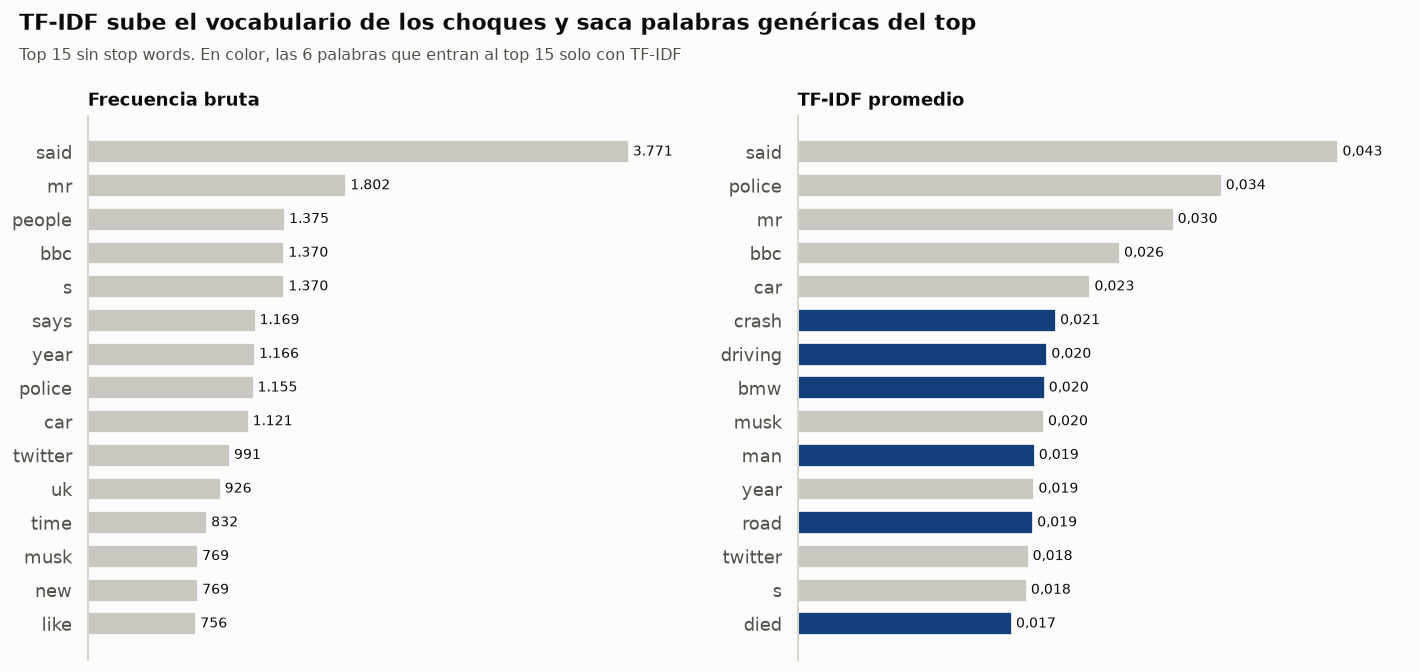

In [13]:
VOCABULARIO = {palabra: i for i, palabra in enumerate(sorted(FRECUENCIAS))}
TERMINOS = np.array(sorted(FRECUENCIAS))


def matriz_conteos(documentos):
    filas, columnas, valores = [], [], []
    for fila, tokens in enumerate(documentos):
        conteo = Counter(t for t in tokens if t in VOCABULARIO)
        filas += [fila] * len(conteo)
        columnas += [VOCABULARIO[t] for t in conteo]
        valores += list(conteo.values())
    return sparse.csr_matrix((valores, (filas, columnas)), shape=(len(documentos), len(VOCABULARIO)), dtype=float)


BOW_CORPUS = matriz_conteos(df["tokens"])
TRANSFORMADOR_TFIDF = TfidfTransformer().fit(BOW_CORPUS)
TFIDF_CORPUS = TRANSFORMADOR_TFIDF.transform(BOW_CORPUS)
esparsidad_bow = 1 - BOW_CORPUS.nnz / np.prod(BOW_CORPUS.shape)

tfidf_medio = np.asarray(TFIDF_CORPUS.mean(axis=0)).ravel()
sin_stop = np.array([t not in STOP for t in TERMINOS])
tabla_terminos = pd.DataFrame({
    "Palabra": TERMINOS[sin_stop],
    "Frecuencia": [FRECUENCIAS[t] for t in TERMINOS[sin_stop]],
    "TF-IDF medio": tfidf_medio[sin_stop],
})
top_frecuencia = tabla_terminos.sort_values(["Frecuencia", "Palabra"], ascending=[False, True]).head(15)
top_tfidf = tabla_terminos.sort_values(["TF-IDF medio", "Palabra"], ascending=[False, True]).head(15)
suben = sorted(set(top_tfidf["Palabra"]) - set(top_frecuencia["Palabra"]))
bajan = sorted(set(top_frecuencia["Palabra"]) - set(top_tfidf["Palabra"]))

print(f"Matriz BoW: {BOW_CORPUS.shape[0]} × {BOW_CORPUS.shape[1]}, esparsidad {esparsidad_bow:.2%}")
print("Suben gracias a TF-IDF:", suben)
print("Salen del top 15:", bajan)

con_crash = df["tokens"].map(lambda tokens: "crash" in tokens)
con_musk = df["tokens"].map(lambda tokens: "musk" in tokens)
print(f"Mediana de tokens: todas {df['longitud'].median():.0f}, con 'crash' {df.loc[con_crash, 'longitud'].median():.0f} ({con_crash.sum()} noticias), con 'musk' {df.loc[con_musk, 'longitud'].median():.0f} ({con_musk.sum()} noticias)")

fig, (izq, der) = plt.subplots(1, 2, figsize=(12, 5.6))
for ax, datos, columna, formato, titulo in [
    (izq, top_frecuencia, "Frecuencia", lambda x: es(x), "Frecuencia bruta"),
    (der, top_tfidf, "TF-IDF medio", lambda x: es(x, 3), "TF-IDF promedio"),
]:
    colores = [ACENTO if p in suben else GRIS_NEUTRO for p in datos["Palabra"]]
    ax.barh(datos["Palabra"], datos[columna], color=colores, height=0.68)
    ax.invert_yaxis()
    for pos, valor in enumerate(datos[columna]):
        ax.text(valor, pos, f" {formato(valor)}", va="center", fontsize=8.5)
    ax.set_title(titulo, fontsize=11)
    ax.set_xticks([])
    ax.grid(False)
    ax.margins(x=0.13)
    sns.despine(ax=ax, bottom=True)
fig.text(0.02, 0.97, "TF-IDF sube el vocabulario de los choques y saca palabras genéricas del top", fontsize=13, fontweight="bold")
fig.text(0.02, 0.925, f"Top 15 sin stop words. En color, las {len(suben)} palabras que entran al top 15 solo con TF-IDF", fontsize=9.5, color=MUTED)
plt.tight_layout(rect=(0, 0, 1, 0.91))
plt.show()

**Hallazgo:** se cumple solo en parte. Salen del top palabras genéricas (`people`, `says`, `time`, `new`, `like`, `uk`) y entran `crash`, `driving`, `bmw`, `road`, `died` y `man`. Pero `said`, `mr` y el fragmento `s` siguen ahí: TF-IDF no limpia el lenguaje de prensa.

El cambio tiene mucho que ver con la longitud. Las 264 noticias con `crash` tienen una mediana de 181 tokens, frente a 354 en todo el corpus, y como cada vector se normaliza, en una nota corta cada palabra pesa más. No es solo que esas palabras sean más informativas.

### Evidencia del límite de BoW

**Hipótesis:** dos frases que piden lo mismo con otras palabras no deberían tener nada en común para BoW. Busqué un caso real en el corpus: dos noticias distintas donde la policía pide información.

In [14]:
FRASE_A = "Officers have appealed for witnesses."
FRASE_B = "Anyone with information was asked to contact police."


def buscar_noticia(frase):
    for doc, texto in zip(df.index, df["content"]):
        if frase in SENTENCE_SPLIT.split(texto):
            return doc
    raise ValueError(f"La frase no está en el corpus: {frase}")


def coseno_conteos(a, b):
    a, b = Counter(a), Counter(b)
    producto = sum(a[t] * b[t] for t in a)
    return producto / (np.sqrt(sum(v ** 2 for v in a.values())) * np.sqrt(sum(v ** 2 for v in b.values())))


tokens_a, tokens_b = tokenizar(FRASE_A), tokenizar(FRASE_B)
display(pd.DataFrame({
    "Frase": [FRASE_A, FRASE_B],
    "Noticia": [buscar_noticia(FRASE_A), buscar_noticia(FRASE_B)],
    "Tokens": [tokens_a, tokens_b],
}))
print("Palabras en común:", sorted(set(tokens_a) & set(tokens_b)))
print(f"Coseno en BoW: {coseno_conteos(tokens_a, tokens_b):.3f}")

,Frase,Noticia,Tokens
0,Officers have appealed for witnesses.,211,"[officers, have, appealed, for, witnesses]"
1,Anyone with information was asked to contact p...,257,"[anyone, with, information, was, asked, to, co..."


Palabras en común: []
Coseno en BoW: 0.000


**Hallazgo:** las frases no comparten ni una palabra, ni siquiera una stop word, así que su coseno es exactamente 0. No son paráfrasis perfectas, pero las dos piden que quien sepa algo lo cuente, y para BoW son tan distintas como dos textos sin relación.

El problema está en la geometría: cada palabra es un eje propio, así que `officers` y `police` son ortogonales aunque hablen de lo mismo. Por eso necesito una representación donde dos palabras distintas puedan quedar cerca, y es lo que pruebo con Word2Vec en la sección 5.

## <a id="s4"></a>4. Concordancias y contexto · 15%

Primero armo un índice con la posición de cada palabra en cada noticia. Con eso, `concordancias()` recibe una palabra, el tamaño de la ventana y la cantidad máxima de resultados, y devuelve:

`Documento | Contexto izquierdo | Palabra | Contexto derecho`

In [15]:
INDICE = {}
for doc, tokens in zip(df.index, df["tokens"]):
    for pos, token in enumerate(tokens):
        INDICE.setdefault(token, []).append((doc, pos))


def concordancias(palabra, ventana=5, cantidad=8, por_documento=None):
    palabra = palabra.lower()
    filas = []
    usados = Counter()
    for doc, pos in INDICE.get(palabra, []):
        if len(filas) == cantidad:
            break
        if por_documento is not None and usados[doc] == por_documento:
            continue
        usados[doc] += 1
        tokens = df.at[doc, "tokens"]
        filas.append({
            "Documento": doc,
            "Contexto izquierdo": " ".join(tokens[max(0, pos - ventana):pos]),
            "Palabra": tokens[pos],
            "Contexto derecho": " ".join(tokens[pos + 1:pos + 1 + ventana]),
        })
    return pd.DataFrame(filas, columns=["Documento", "Contexto izquierdo", "Palabra", "Contexto derecho"])


display(concordancias("government"))

,Documento,Contexto izquierdo,Palabra,Contexto derecho
0,0,take place it says the,government,is working with nhs england
1,3,our calls on the uk,government,as part of proposed legislation
2,3,on tuesday that business and,government,users of twitter may need
3,7,of their frozen accounts before,government,censors moved to blanket block
4,21,dovetail neatly with trump's campaign,government,censorship and persecution complaints about
5,27,below inflation pay awards the,government,has called the demands unreasonable
6,38,for the bbc's account from,government,funded media to say it
7,38,twitter account describing it as,government,funded media mr musk said


Escojo dos palabras con usos distintos, `strike` y `market`, para ver qué puedo inferir de sus contextos. Muestro máximo una concordancia por noticia para que no salgan todas de la misma.

In [16]:
pd.set_option("display.max_colwidth", None)
PALABRAS_CONTEXTO = ["strike", "market"]
for palabra in PALABRAS_CONTEXTO:
    print(f"{palabra}: {FRECUENCIAS[palabra]} apariciones en {len({d for d, _ in INDICE[palabra]})} noticias")
    display(concordancias(palabra, ventana=5, cantidad=8, por_documento=1))

strike: 208 apariciones en 55 noticias


,Documento,Contexto izquierdo,Palabra,Contexto derecho
0,0,to next week's junior doctors,strike,the nhs confederation warns patients
1,27,as the latest junior doctor,strike,coincides with the hottest week
2,39,to stage a five day,strike,in the lead up to
3,130,start voting on whether to,strike,over a continuing dispute over
4,164,medics say this week's joint,strike,action by consultants and junior
5,170,staged a three day joint,strike,at the start of october
6,183,medical association bma will take,strike,action from april to april
7,229,are currently being balloted on,strike,action unions including the british


market: 236 apariciones en 110 noticias


,Documento,Contexto izquierdo,Palabra,Contexto derecho
0,3,media firm to the stock,market,in just a few years
1,15,operational resilience in an evolving,market,futureproof the plant's success and
2,18,releasing a lower price mass,market,ev however tesla has already
3,19,bn bn wiped off its,market,value on tuesday one analyst
4,26,to rise it's a lucrative,market,he said car thefts he
5,34,few years time tesla's mass,market,robots will be tested by
6,45,house in falmouth's competitive rental,market,she met pete and lee
7,48,estimates of the lithium industry's,market,value vary with one report


**Hipótesis:** con ±2 debería ver colocaciones, y con ±10 el tema de la noticia.

In [17]:
def coocurrencias(palabra, ventana):
    conteo = Counter()
    for doc, pos in INDICE.get(palabra, []):
        tokens = df.at[doc, "tokens"]
        contexto = tokens[max(0, pos - ventana):pos] + tokens[pos + 1:pos + 1 + ventana]
        conteo.update(t for t in contexto if t not in STOP and t != palabra)
    return conteo


VENTANAS = [2, 5, 10]
for palabra in PALABRAS_CONTEXTO:
    conteos = {v: coocurrencias(palabra, v) for v in VENTANAS}
    display(pd.DataFrame({
        f"±{v}": [f"{w} ({f})" for w, f in conteos[v].most_common(10)] for v in VENTANAS
    }).rename_axis(palabra))
    tops = {v: {w for w, _ in conteos[v].most_common(50)} for v in VENTANAS}
    print(
        f"{palabra}: palabras de contexto distintas por ventana {[len(conteos[v]) for v in VENTANAS]}; "
        f"del top 50 compartidas ±2/±5: {len(tops[2] & tops[5])}, ±2/±10: {len(tops[2] & tops[10])}"
    )

,±2,±5,±10
strike,,,
0,action (64),action (69),doctors (88)
1,day (18),doctors (35),action (80)
2,junior (17),junior (31),junior (71)
3,doctors (11),said (20),said (47)
4,nhs (11),day (20),pay (36)
5,said (7),nhs (17),bma (35)
6,days (7),consultants (17),nhs (29)
7,england (6),england (14),consultants (26)
8,doctor (4),patient (11),england (26)


strike: palabras de contexto distintas por ventana [159, 416, 730]; del top 50 compartidas ±2/±5: 24, ±2/±10: 19


,±2,±5,±10
market,,,
0,stock (16),stock (18),said (27)
1,value (13),car (18),car (21)
2,car (13),value (13),electric (20)
3,ev (9),said (13),stock (19)
4,electric (9),electric (12),mr (16)
5,research (7),ev (10),says (16)
6,share (6),research (9),s (15)
7,manipulation (6),mr (8),new (15)
8,labour (6),share (8),value (14)


market: palabras de contexto distintas por ventana [319, 823, 1456]; del top 50 compartidas ±2/±5: 27, ±2/±10: 26


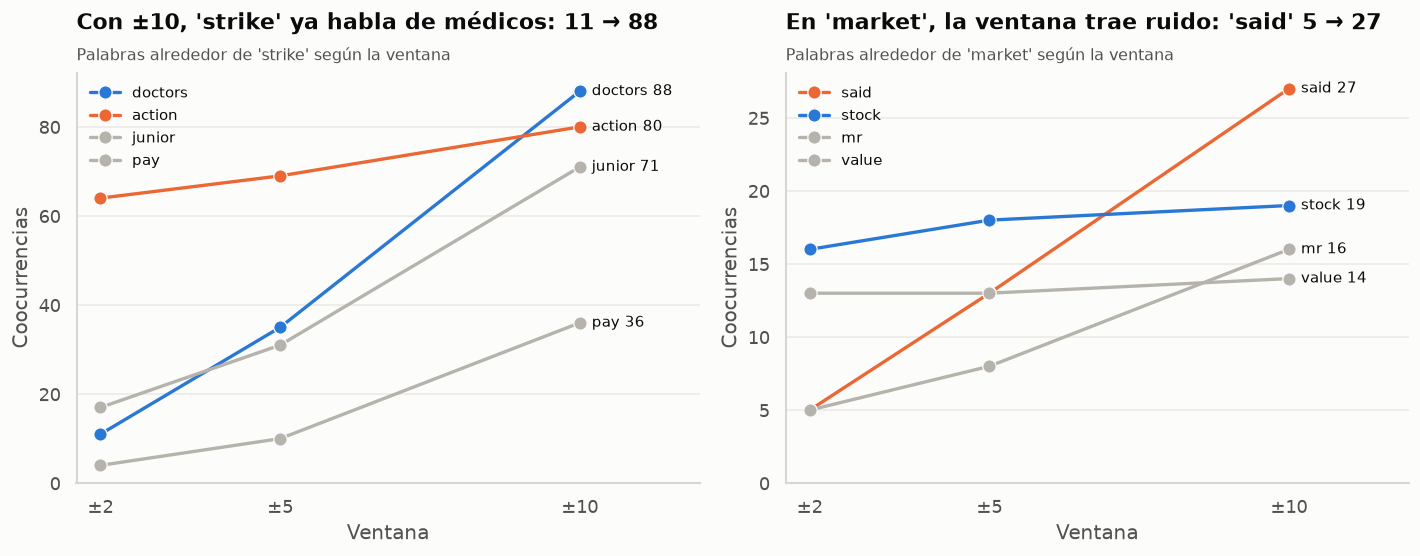

In [18]:
SEGUIDAS = {
    "strike": {"doctors": BLUE, "action": ORANGE, "junior": GRAY, "pay": GRAY},
    "market": {"said": ORANGE, "stock": BLUE, "mr": GRAY, "value": GRAY},
}
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (palabra, colores) in zip(ejes, SEGUIDAS.items()):
    conteos = {v: coocurrencias(palabra, v) for v in VENTANAS}
    datos = pd.DataFrame([
        {"Ventana": v, "Palabra de contexto": w, "Coocurrencias": conteos[v][w]}
        for v in VENTANAS for w in colores
    ])
    sns.lineplot(
        datos, x="Ventana", y="Coocurrencias", hue="Palabra de contexto", palette=colores,
        marker="o", markersize=8, linewidth=2, markeredgecolor=SURFACE, ax=ax,
    )
    for w in colores:
        ax.text(10.2, conteos[10][w], f"{w} {es(conteos[10][w])}", va="center", fontsize=9)
    ax.set(xticks=VENTANAS, xticklabels=[f"±{v}" for v in VENTANAS], xlim=(1.6, 12), ylim=(0, None), xlabel="Ventana")
    ax.legend(loc="upper left", fontsize=9, title=None)
    ax.grid(axis="x", visible=False)

doctors = [coocurrencias("strike", v)["doctors"] for v in VENTANAS]
said = [coocurrencias("market", v)["said"] for v in VENTANAS]
titular(ejes[0], f"Con ±10, 'strike' ya habla de médicos: {es(doctors[0])} → {es(doctors[-1])}", "Palabras alrededor de 'strike' según la ventana")
titular(ejes[1], f"En 'market', la ventana trae ruido: 'said' {es(said[0])} → {es(said[-1])}", "Palabras alrededor de 'market' según la ventana")
plt.tight_layout()
plt.show()

**`strike`** (208 apariciones en 55 noticias) es en las filas vistas una huelga: `junior doctors strike`, `strike action`, `balloted on strike`. Funciona como sustantivo y como verbo (`whether to strike`), y sus contextos se parecen entre sí porque 44 de esas 55 noticias también mencionan `doctors`.

**`market`** (236 apariciones en 110 noticias) es más dispersa: `stock market`, `mass market`, `rental market`, `market value`. Lo que aclara el sentido es la palabra de al lado, porque puede hablar de bolsa, de carros o de vivienda.

**Hallazgo: efecto de la ventana.** Con ±2 aparece la colocación: `action` junto a `strike` (64), y `stock` (16) y `value` (13) junto a `market`. Con ±10 aparece el tema: alrededor de `strike`, `doctors` pasa de 11 a 88 y entran `pay` (36) y `bma` (35). También entra ruido: en `market` suben `said`, `mr` y `says`, que no dicen nada del mercado.

Las palabras de contexto distintas crecen mucho con la ventana (`strike`: 159, 416 y 730; `market`: 319, 823 y 1.456), y de las 50 más frecuentes con ±2 solo 19 y 26 siguen entre las 50 de ±10. Esto conecta con la hipótesis distribucional: conocemos una palabra por su compañía, y la ventana decide qué compañía miramos. Con una ventana corta veo más bien sintaxis; con una larga, el tema.

## <a id="s5"></a>5. Word2Vec · 20%

`entrenar_word2vec` entrena sobre las oraciones del corpus con `vector_size=50`, `min_count=5`, `workers=1` y `seed=42`, y recibe la ventana como parámetro.

Lo demás lo dejo en los valores por defecto de gensim (CBOW y 5 épocas), y agrego `modelo_10` para comparar también con una ventana grande. Paso un `hashfxn` estable para que los vectores no dependan de `PYTHONHASHSEED`.

Durante el entrenamiento, gensim 4.4 imprime un aviso interno (`Exception ignored in: ...our_dot_float`), que oculto con `%%capture`. No es un error del notebook: lo comprobé entrenando dos veces y con tres combinaciones de NumPy y SciPy, y los vectores salieron idénticos.

In [19]:
%%capture --no-stdout --no-display
ORACIONES = [oracion for oraciones in df["oraciones"] for oracion in oraciones]


def stable_hash(texto):
    return zlib.crc32(texto.encode("utf-8"))


def entrenar_word2vec(ventana, seed=42):
    return Word2Vec(
        sentences=ORACIONES,
        vector_size=50,
        window=ventana,
        min_count=5,
        workers=1,
        seed=seed,
        hashfxn=stable_hash,
    )


modelo_2 = entrenar_word2vec(2)
modelo_5 = entrenar_word2vec(5)
modelo_10 = entrenar_word2vec(10)
tokens_modelo = sum(FRECUENCIAS[w] for w in modelo_2.wv.index_to_key)
print("Vocabulario de los modelos:", len(modelo_2.wv), "de", n_palabras, "palabras")
print(f"Esas palabras cubren {tokens_modelo / n_tokens:.1%} de los tokens.")
print(f"Tokens por oración: media {np.mean(list(map(len, ORACIONES))):.1f}, mediana {np.median(list(map(len, ORACIONES))):.0f}")

Vocabulario de los modelos: 7924 de 25616 palabras
Esas palabras cubren 94.3% de los tokens.
Tokens por oración: media 22.0, mediana 19


### De disperso a denso

**Hipótesis:** la diferencia entre las dos representaciones debería verse a simple vista: casi todo vacío en BoW y todo lleno en Word2Vec.

Muestra BoW 100×100: 2.4% de celdas con algún valor
Matriz BoW completa: 99.02% de ceros
Matriz Word2Vec completa (7924, 50): 0.00% de ceros


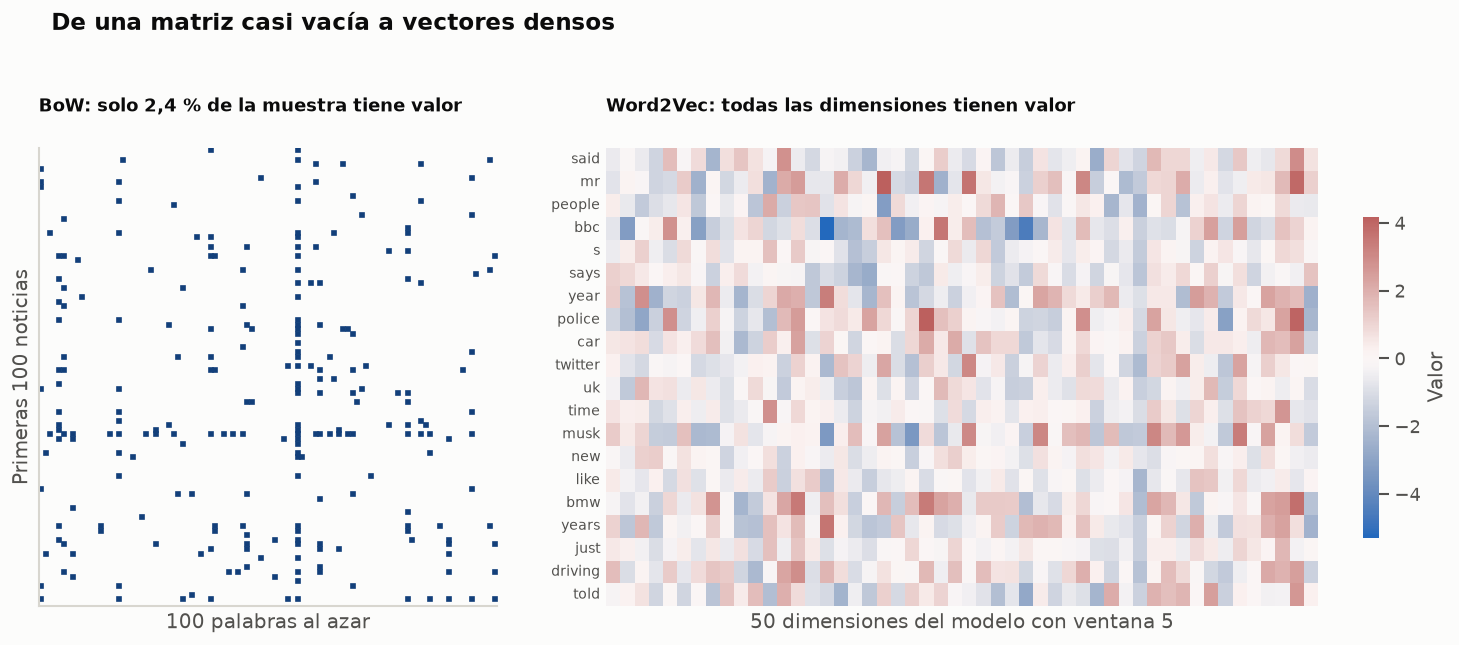

In [20]:
rng_muestra = np.random.default_rng(SEED)
vocabulario_comun = np.array(sorted(modelo_5.wv.index_to_key))
columnas_spy = sorted(VOCABULARIO[p] for p in rng_muestra.choice(vocabulario_comun, 100, replace=False))
muestra_bow = BOW_CORPUS[:100][:, columnas_spy]
llenas = muestra_bow.nnz / np.prod(muestra_bow.shape)

palabras_mapa = [p for p, _ in FRECUENCIAS.most_common() if p not in STOP and p in modelo_5.wv][:20]
vectores_mapa = np.array([modelo_5.wv[p] for p in palabras_mapa])
nulos_w2v = np.mean(modelo_5.wv.vectors == 0)
print(f"Muestra BoW 100×100: {llenas:.1%} de celdas con algún valor")
print(f"Matriz BoW completa: {esparsidad_bow:.2%} de ceros")
print(f"Matriz Word2Vec completa {modelo_5.wv.vectors.shape}: {nulos_w2v:.2%} de ceros")

fig, (izq, der) = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1, 1.7]})
izq.spy(muestra_bow, markersize=2.2, color=ACENTO)
izq.set_title(f"BoW: solo {es(llenas * 100, 1)} % de la muestra tiene valor", fontsize=11, pad=22)
izq.set_xlabel("100 palabras al azar")
izq.set_ylabel("Primeras 100 noticias")
izq.xaxis.set_ticks_position("bottom")
izq.set_xticks([])
izq.set_yticks([])
izq.grid(False)
sns.heatmap(vectores_mapa, cmap="vlag", center=0, yticklabels=palabras_mapa, xticklabels=False, cbar_kws={"shrink": 0.7, "label": "Valor"}, ax=der)
der.set_title("Word2Vec: todas las dimensiones tienen valor", fontsize=11, pad=22)
der.set_xlabel("50 dimensiones del modelo con ventana 5")
der.tick_params(axis="y", length=0, labelsize=8.5, rotation=0)
fig.suptitle("De una matriz casi vacía a vectores densos", fontsize=14, fontweight="bold", x=0.06, ha="left", y=1.03)
plt.tight_layout()
plt.show()

**Hallazgo:** en la muestra, solo el 2,4 % de las celdas de BoW tiene valor, y eso que tomé palabras con al menos 5 apariciones. En la matriz completa, el 99,02 % son ceros. Word2Vec no tiene ningún cero, pero sus 50 dimensiones no se pueden leer una por una: gano densidad y pierdo la interpretación directa que tenía una columna de BoW.

### Vecinos

`vecinos` recibe una palabra, un modelo y `n`, y devuelve los vecinos más cercanos con su similitud.

**Hipótesis:** con ventana pequeña deberían salir palabras que ocupan un lugar parecido en la oración, y con ventana grande, palabras del mismo tema.

In [21]:
def vecinos(palabra, modelo, n=5):
    palabra = palabra.lower()
    if palabra not in modelo.wv:
        return pd.DataFrame(columns=["Vecino", "Similitud"])
    return pd.DataFrame(modelo.wv.most_similar(palabra, topn=n), columns=["Vecino", "Similitud"]).round(3)


PALABRA = "government"

display(vecinos(PALABRA, modelo_2))
display(vecinos(PALABRA, modelo_5))
display(vecinos(PALABRA, modelo_10))

,Vecino,Similitud
0,bma,0.850
1,nuffield,0.738
2,minister,0.733
3,lefebvre,0.719
4,trust,0.714


,Vecino,Similitud
0,bma,0.853
1,union,0.823
2,vaccine,0.775
3,welsh,0.750
4,trust,0.742


,Vecino,Similitud
0,union,0.833
1,bma,0.827
2,nuffield,0.810
3,medical,0.809
4,welsh,0.797


In [22]:
MODELOS = {2: modelo_2, 5: modelo_5, 10: modelo_10}
PALABRAS_COMPARAR = ["government", "strike", "market", "doctors", "tesla", "good"]

for palabra in PALABRAS_COMPARAR:
    display(pd.DataFrame({
        f"Ventana {v}": [f"{w} ({s:.2f})" for w, s in m.wv.most_similar(palabra, topn=8)]
        for v, m in MODELOS.items()
    }).rename_axis(f"{palabra} ({FRECUENCIAS[palabra]})"))

,Ventana 2,Ventana 5,Ventana 10
government (432),,,
0,bma (0.85),bma (0.85),union (0.83)
1,nuffield (0.74),union (0.82),bma (0.83)
2,minister (0.73),vaccine (0.77),nuffield (0.81)
3,lefebvre (0.72),welsh (0.75),medical (0.81)
4,trust (0.71),trust (0.74),welsh (0.80)
5,council (0.71),scottish (0.73),pay (0.79)
6,union (0.71),blockchains (0.73),offer (0.78)
7,fans (0.71),nhs (0.73),health (0.78)


,Ventana 2,Ventana 5,Ventana 10
strike (208),,,
0,walkout (0.90),action (0.94),junior (0.97)
1,industrial (0.90),consultants (0.91),action (0.97)
2,action (0.88),dispute (0.91),consultants (0.96)
3,dispute (0.87),walkout (0.89),doctors (0.96)
4,increase (0.86),doctor (0.87),doctor (0.95)
5,rise (0.85),strikes (0.86),walkout (0.92)
6,hour (0.83),junior (0.86),medical (0.90)
7,extra (0.82),industrial (0.86),dispute (0.90)


,Ventana 2,Ventana 5,Ventana 10
market (236),,,
0,industry (0.94),economy (0.96),economy (0.95)
1,grid (0.94),industry (0.95),ev (0.95)
2,current (0.93),global (0.95),global (0.95)
3,economy (0.93),production (0.95),population (0.94)
4,index (0.93),oil (0.94),biggest (0.94)
5,russian (0.93),population (0.94),sales (0.94)
6,oil (0.93),value (0.94),value (0.93)
7,trade (0.93),longevity (0.94),chinese (0.93)


,Ventana 2,Ventana 5,Ventana 10
doctors (444),,,
0,doctor (0.90),junior (0.88),action (0.96)
1,consultants (0.80),consultants (0.87),strike (0.96)
2,nhs (0.73),doctor (0.87),junior (0.95)
3,staff (0.71),action (0.84),consultants (0.94)
4,england (0.67),nhs (0.83),doctor (0.92)
5,bosses (0.66),strike (0.83),nhs (0.92)
6,leaders (0.65),pay (0.83),pay (0.89)
7,eligible (0.64),strikes (0.76),bma (0.89)


,Ventana 2,Ventana 5,Ventana 10
tesla (536),,,
0,company (0.85),company (0.85),company (0.93)
1,firm (0.81),billionaire (0.82),richest (0.91)
2,billionaire (0.81),elon (0.81),shares (0.89)
3,trump (0.80),takeover (0.81),bn (0.89)
4,himself (0.78),firm (0.80),billionaire (0.88)
5,maradona (0.78),shares (0.80),stake (0.87)
6,lancaster (0.78),musk (0.78),firm (0.87)
7,poll (0.77),bought (0.77),takeover (0.86)


,Ventana 2,Ventana 5,Ventana 10
good (204),,,
0,bad (0.94),really (0.97),thing (0.97)
1,big (0.93),thing (0.96),something (0.96)
2,thing (0.93),something (0.96),things (0.96)
3,important (0.93),quite (0.95),really (0.95)
4,little (0.92),actually (0.95),hard (0.95)
5,difficult (0.92),always (0.95),actually (0.95)
6,possible (0.92),too (0.95),going (0.94)
7,quite (0.91),hard (0.94),doing (0.94)


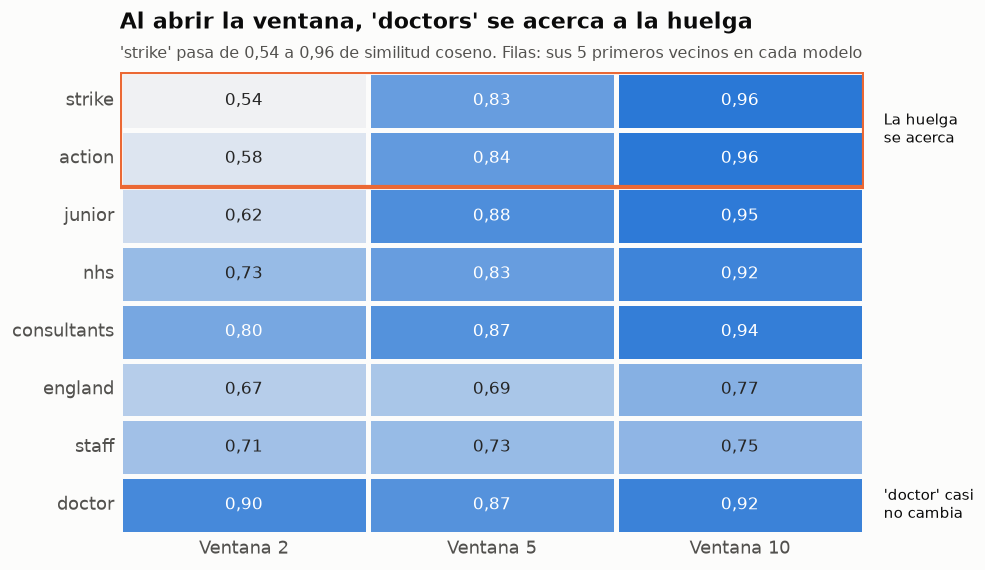

In [23]:
PALABRA_MAPA = "doctors"
filas_mapa = {
    w: {f"Ventana {v}": float(m.wv.similarity(PALABRA_MAPA, w)) for v, m in MODELOS.items()}
    for w in sorted({w for m in MODELOS.values() for w, _ in m.wv.most_similar(PALABRA_MAPA, topn=5)})
}
mapa = pd.DataFrame(filas_mapa).T
mapa = mapa.loc[(mapa["Ventana 10"] - mapa["Ventana 2"]).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(
    mapa, annot=mapa.map(lambda x: es(x, 2)), fmt="", cmap=sns.light_palette(BLUE, as_cmap=True),
    linewidths=2, linecolor=SURFACE, cbar=False, annot_kws={"fontsize": 10}, ax=ax,
)
ax.tick_params(axis="y", rotation=0, length=0)
ax.tick_params(axis="x", length=0)
ax.grid(False)
ax.add_patch(Rectangle((0, 0), 3, 2, fill=False, edgecolor=ORANGE, lw=2.5))
ax.text(3.08, 1, "La huelga\nse acerca", va="center", fontsize=9)
ax.text(3.08, 7.5, "'doctor' casi\nno cambia", va="center", fontsize=9)
strike = mapa.loc["strike"]
titular(
    ax,
    "Al abrir la ventana, 'doctors' se acerca a la huelga",
    f"'strike' pasa de {es(strike.iloc[0], 2)} a {es(strike.iloc[-1], 2)} de similitud coseno. Filas: sus 5 primeros vecinos en cada modelo",
)
ax.set(xlabel=None, ylabel=None)
plt.show()

In [24]:
%%capture --no-stdout --no-display
SEMILLAS = [42, 7, 2026]
modelos_semilla = {(v, s): entrenar_word2vec(v, seed=s) for v in VENTANAS for s in SEMILLAS}


def neighbors(palabra, modelo, n=10):
    return {w for w, _ in modelo.wv.most_similar(palabra, topn=n)}


def jaccard(a, b):
    return len(a & b) / len(a | b)


def mean_overlap(palabras, pares):
    return float(np.mean([
        jaccard(neighbors(p, modelos_semilla[a]), neighbors(p, modelos_semilla[b]))
        for p in palabras for a, b in pares
    ]))


# Same seed, different window: what the window changes (plus noise).
pares_ventana = [((a, s), (b, s)) for a, b in combinations(VENTANAS, 2) for s in SEMILLAS]
# Same window, different seed: pure training noise.
pares_semilla = [((v, a), (v, b)) for v in VENTANAS for a, b in combinations(SEMILLAS, 2)]

candidatas = sorted(
    w for w in modelo_2.wv.index_to_key
    if w not in STOP and len(w) >= 3 and "'" not in w
)
franjas = {"Alta (200+)": (200, 10**9), "Media (50-199)": (50, 199), "Baja (5-19)": (5, 19)}
rng = random.Random(SEED)
filas = []
for nombre, (low, high) in franjas.items():
    grupo = [w for w in candidatas if low <= FRECUENCIAS[w] <= high]
    muestra = rng.sample(grupo, min(30, len(grupo)))
    filas.append({
        "Frecuencia": nombre,
        "Palabras en la franja": len(grupo),
        "Palabras medidas": len(muestra),
        "Jaccard entre ventanas": round(mean_overlap(muestra, pares_ventana), 3),
        "Jaccard entre semillas": round(mean_overlap(muestra, pares_semilla), 3),
    })
display(pd.DataFrame(filas))

por_par = [{
    "Ventanas": f"{a} vs {b}",
    "Jaccard": round(mean_overlap(
        [w for w in candidatas if FRECUENCIAS[w] >= 200],
        [((a, s), (b, s)) for s in SEMILLAS],
    ), 3),
} for a, b in combinations(VENTANAS, 2)]
display(pd.DataFrame(por_par))

,Frecuencia,Palabras en la franja,Palabras medidas,Jaccard entre ventanas,Jaccard entre semillas
0,Alta (200+),151,30,0.314,0.504
1,Media (50-199),915,30,0.134,0.228
2,Baja (5-19),4886,30,0.029,0.048


,Ventanas,Jaccard
0,2 vs 5,0.298
1,2 vs 10,0.174
2,5 vs 10,0.339


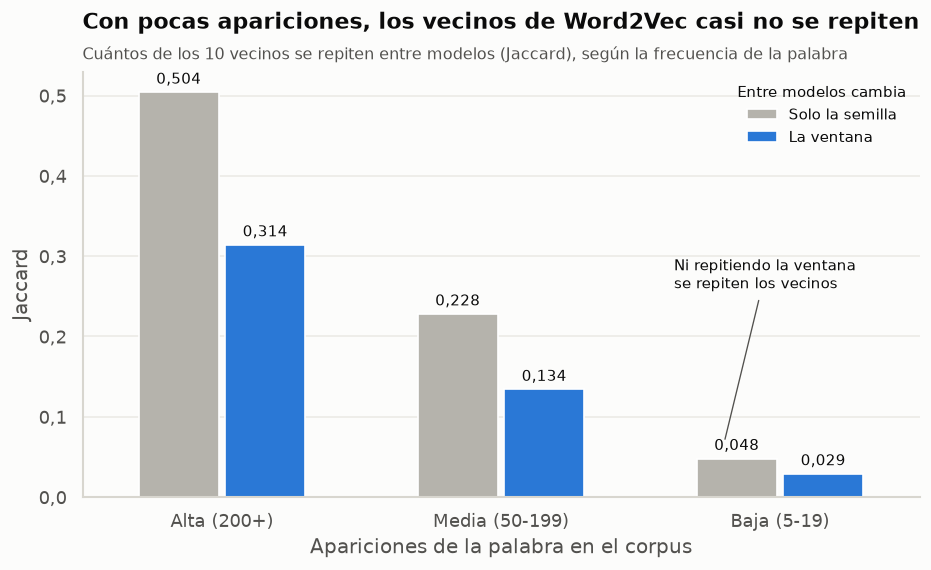

In [25]:
ruido = pd.DataFrame(filas).melt(
    id_vars="Frecuencia",
    value_vars=["Jaccard entre semillas", "Jaccard entre ventanas"],
    var_name="Qué cambia",
    value_name="Jaccard",
)
ruido["Qué cambia"] = ruido["Qué cambia"].map({
    "Jaccard entre semillas": "Solo la semilla",
    "Jaccard entre ventanas": "La ventana",
})
baja_semillas = ruido.query("Frecuencia == 'Baja (5-19)' and `Qué cambia` == 'Solo la semilla'")["Jaccard"].iloc[0]

fig, ax = plt.subplots(figsize=(9, 4.6))
sns.barplot(
    ruido, x="Frecuencia", y="Jaccard", hue="Qué cambia",
    palette={"Solo la semilla": GRAY, "La ventana": BLUE}, width=0.62, gap=0.08, saturation=1, ax=ax,
)
for contenedor in ax.containers:
    ax.bar_label(contenedor, labels=[es(b.get_height(), 3) for b in contenedor], padding=3, fontsize=9)
nota(ax, "Ni repitiendo la ventana\nse repiten los vecinos", (1.8, baja_semillas + 0.02), (1.62, 0.26))
titular(
    ax,
    "Con pocas apariciones, los vecinos de Word2Vec casi no se repiten",
    "Cuántos de los 10 vecinos se repiten entre modelos (Jaccard), según la frecuencia de la palabra",
)
ax.set(xlabel="Apariciones de la palabra en el corpus", ylabel="Jaccard", ylim=(0, None))
ax.margins(y=0.14)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right", title="Entre modelos cambia", fontsize=9, title_fontsize=9)
ticks_es(ax.yaxis, 1)
plt.show()

**Hallazgo: qué cambió.** `government` conserva a `bma` y `trust`, pero con ventana 2 trae `minister` y `nuffield`, y con ventana 5 trae `union`, `vaccine` y `welsh`. `doctors` lo muestra más claro: con ventana 2 sus vecinos son `doctor`, `consultants`, `nhs` y `staff`, palabras que podrían ocupar un lugar parecido en la oración. Con ventana 10 son `action`, `strike` y `junior`: ya no es quién es, sino de qué se habla.

**En las palabras frecuentes no es azar.** Mido cuántos de los 10 vecinos se repiten (Jaccard). En palabras con 200 o más apariciones da 0,314 entre ventanas y 0,504 si solo cambio la semilla, y el cambio crece con la distancia entre ventanas (0,298 de 2 a 5, 0,174 de 2 a 10).

**La frecuencia importa.** En palabras con 5 a 19 apariciones, los vecinos casi no se repiten ni cambiando solo la semilla (0,048). Ahí no se puede atribuirle nada a la ventana. `min_count=5` deja 7.924 de las 25.616 palabras, que cubren el 94,3 % de los tokens.

**No tienen que ser sinónimos.** `bad` es el primer vecino de `good` con ventana 2 (0,94), y `sell` es el primero de `buy` con ventana 5 (0,94). Son opuestos, pero aparecen en los mismos contextos.

### Mapa de vecinos

**Hipótesis:** si escojo cinco palabras de temas distintos del corpus, sus vecinos deberían formar grupos separados. Escogí `doctors`, `police`, `tesla`, `court` y `energy` porque son frecuentes y corresponden a historias que ya aparecieron en las secciones anteriores.

,Palabras
Ancla,
doctors,"doctors, junior, consultants, doctor, action, nhs, strike, pay, strikes, bma, rise"
police,"police, force, officers, crash, collision, alerted, pc, spokesperson, sgt, investigation, avon"
tesla,"tesla, company, billionaire, elon, takeover, firm, shares, musk, bought, reinstated, stake"
court,"court, inquest, hearing, trial, jury, crown, heard, judge, benn, sentencing, scene"
energy,"energy, technology, emissions, data, storage, carbon, global, power, digital, economy, economic"


Palabras proyectadas: 55
Silueta en 50 dimensiones (coseno): 0.528; en la proyección t-SNE: 0.713


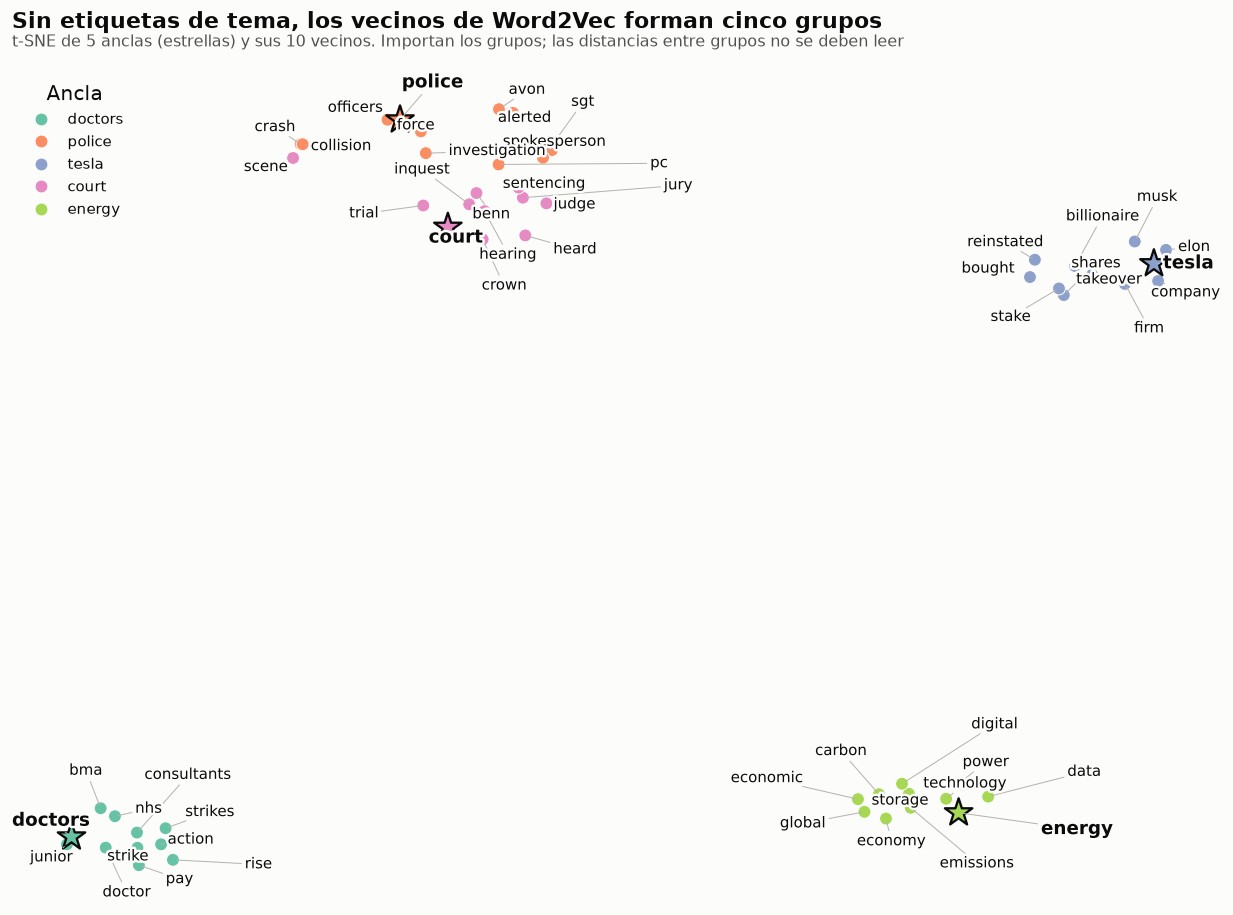

In [26]:
ANCLAS = ["doctors", "police", "tesla", "court", "energy"]
palabras_tsne, grupos_tsne, usadas = [], [], set(ANCLAS)
for ancla in ANCLAS:
    palabras_tsne.append(ancla)
    grupos_tsne.append(ancla)
    nuevas = [p for p, _ in modelo_5.wv.most_similar(ancla, topn=30) if p not in usadas and p not in STOP][:10]
    usadas.update(nuevas)
    palabras_tsne += nuevas
    grupos_tsne += [ancla] * len(nuevas)

vectores_tsne = np.array([modelo_5.wv[p] for p in palabras_tsne])
proyeccion = TSNE(n_components=2, perplexity=10, metric="cosine", init="pca", random_state=SEED).fit_transform(vectores_tsne)
datos_tsne = pd.DataFrame({"x": proyeccion[:, 0], "y": proyeccion[:, 1], "Palabra": palabras_tsne, "Ancla": grupos_tsne})
silueta_50 = silhouette_score(vectores_tsne, grupos_tsne, metric="cosine")
silueta_2 = silhouette_score(proyeccion, grupos_tsne)
display(datos_tsne.groupby("Ancla", sort=False)["Palabra"].apply(", ".join).to_frame("Palabras"))
print(f"Palabras proyectadas: {len(palabras_tsne)}")
print(f"Silueta en 50 dimensiones (coseno): {silueta_50:.3f}; en la proyección t-SNE: {silueta_2:.3f}")

colores_tsne = dict(zip(ANCLAS, sns.color_palette("Set2", len(ANCLAS))))
fig, ax = plt.subplots(figsize=(13, 9))
sns.scatterplot(datos_tsne, x="x", y="y", hue="Ancla", palette=colores_tsne, s=60, edgecolor=SURFACE, ax=ax)
es_ancla = datos_tsne["Palabra"].isin(ANCLAS)
sns.scatterplot(datos_tsne[es_ancla], x="x", y="y", hue="Ancla", palette=colores_tsne, s=300, marker="*", edgecolor=INK, legend=False, ax=ax)
etiquetas = [
    ax.text(fila.x, fila.y, fila.Palabra, fontsize=11 if fila.Palabra in ANCLAS else 9, fontweight="bold" if fila.Palabra in ANCLAS else "normal", zorder=5, path_effects=[withStroke(linewidth=3, foreground=SURFACE)])
    for fila in datos_tsne.itertuples()
]
adjust_text(
    etiquetas, x=datos_tsne["x"].to_numpy(), y=datos_tsne["y"].to_numpy(), ax=ax, expand=(1.25, 1.5),
    force_text=(0.4, 0.6), max_move=None, iter_lim=500, arrowprops=dict(arrowstyle="-", color=GRAY, lw=0.6),
)
ax.set(xlabel=None, ylabel=None, xticks=[], yticks=[])
ax.grid(False)
sns.despine(ax=ax, left=True, bottom=True)
titular(ax, "Sin etiquetas de tema, los vecinos de Word2Vec forman cinco grupos", "t-SNE de 5 anclas (estrellas) y sus 10 vecinos. Importan los grupos; las distancias entre grupos no se deben leer")
ax.legend(loc="best", title="Ancla", fontsize=9)
plt.show()

**Hallazgo:** los grupos aparecen, con dos advertencias. La primera es que el resultado está en parte construido, porque cada grupo sale de los vecinos de su ancla. La segunda es que t-SNE exagera la separación: la silueta es 0,528 en las 50 dimensiones originales y 0,713 en el mapa.

Lo más informativo son las fronteras. `police` y `court` quedan juntos, y `crash` entra con `police` mientras `scene` entra con `court`: el modelo refleja cómo se cuentan las noticias judiciales y de tránsito, no una clasificación de temas.

### Cinco oraciones, dos representaciones

**Hipótesis:** con Word2Vec, O1 y O2 deberían quedar cerca (testigos), igual que O3 y O4 (huelga), mientras que O5 debería quedar lejos de las demás. Represento cada oración con el promedio de sus vectores y uso 20.000 pares al azar como referencia, porque un coseno alto no dice mucho sin saber cuánto da normalmente.

,Oración,Noticia
O1,Officers have appealed for witnesses.,211
O2,Anyone with information was asked to contact police.,257
O3,The walkout is due to start on Tuesday.,0
O4,Junior doctors have so far taken 39 days of strike action during this dispute.,832
O5,Mr Musk announced a plan to buy Twitter for $54.20 per share in April.,442


Oraciones de referencia: 12441, con 20.000 pares al azar
Word2Vec, pares al azar: mediana 0.679, percentil 5 0.338, percentil 95 0.881
O1 y O2 (testigos): TF-IDF 0.000; Word2Vec 0.786, por encima del 76% de los pares al azar
O3 y O4 (huelga): TF-IDF 0.000; Word2Vec 0.602, por encima del 35% de los pares al azar
O3 y O5 (sin relación): TF-IDF 0.014; Word2Vec 0.712, por encima del 58% de los pares al azar
officers/police: 0.874; witnesses/information: 0.870; walkout/strike: 0.894


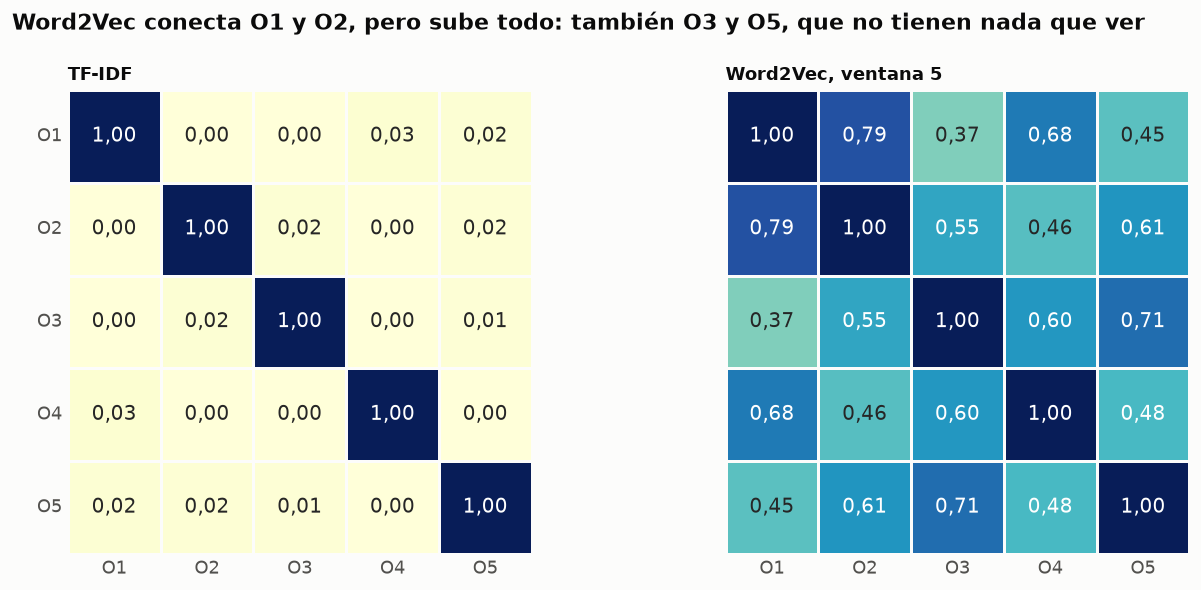

In [27]:
ORACIONES_MAPA = [
    FRASE_A,
    FRASE_B,
    "The walkout is due to start on Tuesday.",
    "Junior doctors have so far taken 39 days of strike action during this dispute.",
    "Mr Musk announced a plan to buy Twitter for $54.20 per share in April.",
]
ETIQUETAS_MAPA = [f"O{i}" for i in range(1, 6)]
display(pd.DataFrame({
    "Oración": ORACIONES_MAPA,
    "Noticia": [buscar_noticia(o) for o in ORACIONES_MAPA],
}, index=ETIQUETAS_MAPA))


def vector_oracion(tokens, modelo):
    return np.mean([modelo.wv[t] for t in tokens if t in modelo.wv], axis=0)


tokens_mapa = [tokenizar(o) for o in ORACIONES_MAPA]
sim_tfidf = cosine_similarity(TRANSFORMADOR_TFIDF.transform(matriz_conteos(tokens_mapa)))
sim_w2v = cosine_similarity(np.array([vector_oracion(t, modelo_5) for t in tokens_mapa]))

oraciones_base = [o for o in ORACIONES if 4 <= len(o) <= 20 and sum(t in modelo_5.wv for t in o) >= 4]
rng_pares = np.random.default_rng(SEED)
pares_a = rng_pares.integers(0, len(oraciones_base), 20000)
pares_b = rng_pares.integers(0, len(oraciones_base), 20000)


def coseno_azar_w2v(modelo):
    vectores = normalize(np.array([vector_oracion(o, modelo) for o in oraciones_base]))
    return np.sum(vectores[pares_a] * vectores[pares_b], axis=1)


def coseno_azar_disperso(matriz):
    matriz = normalize(matriz)
    return np.asarray(matriz[pares_a].multiply(matriz[pares_b]).sum(axis=1)).ravel()


azar_w2v = coseno_azar_w2v(modelo_5)
print(f"Oraciones de referencia: {len(oraciones_base)}, con 20.000 pares al azar")
print(f"Word2Vec, pares al azar: mediana {np.median(azar_w2v):.3f}, percentil 5 {np.percentile(azar_w2v, 5):.3f}, percentil 95 {np.percentile(azar_w2v, 95):.3f}")
for i, j, nombre in [(0, 1, "O1 y O2 (testigos)"), (2, 3, "O3 y O4 (huelga)"), (2, 4, "O3 y O5 (sin relación)")]:
    print(f"{nombre}: TF-IDF {sim_tfidf[i, j]:.3f}; Word2Vec {sim_w2v[i, j]:.3f}, por encima del {np.mean(azar_w2v < sim_w2v[i, j]):.0%} de los pares al azar")
print(f"officers/police: {modelo_5.wv.similarity('officers', 'police'):.3f}; witnesses/information: {modelo_5.wv.similarity('witnesses', 'information'):.3f}; walkout/strike: {modelo_5.wv.similarity('walkout', 'strike'):.3f}")

fig, (izq, der) = plt.subplots(1, 2, figsize=(11.5, 5), sharey=True)
for ax, matriz, titulo in [(izq, sim_tfidf, "TF-IDF"), (der, sim_w2v, "Word2Vec, ventana 5")]:
    sns.heatmap(
        matriz, vmin=0, vmax=1, cmap="YlGnBu", annot=np.vectorize(lambda x: es(x, 2))(matriz), fmt="",
        square=True, linewidths=1.5, linecolor=SURFACE, cbar=False,
        xticklabels=ETIQUETAS_MAPA, yticklabels=ETIQUETAS_MAPA, ax=ax,
    )
    ax.set_title(titulo, fontsize=11)
    ax.tick_params(length=0, rotation=0)
    ax.grid(False)
fig.suptitle("Word2Vec conecta O1 y O2, pero sube todo: también O3 y O5, que no tienen nada que ver", fontsize=13, fontweight="bold", x=0.06, ha="left")
plt.tight_layout()
plt.show()

**Hallazgo:** la hipótesis se cumple a medias. TF-IDF deja casi todo en 0, así que no distingue pares relacionados de los que no lo están. Word2Vec sí acerca O1 y O2 (0,79), pero dos oraciones al azar ya dan 0,68 de mediana, así que ese par solo supera al 76 % de los pares al azar.

El caso de la huelga no se sostiene: O3 y O4 dan 0,60, por debajo de la mediana, y O3 y O5, que no tienen relación, dan 0,71. Sin embargo, las palabras por separado sí están cerca: `officers`/`police` 0,87, `witnesses`/`information` 0,87 y `walkout`/`strike` 0,89. Word2Vec mejora la relación entre palabras, pero promediarlas no alcanza para capturar el sentido de una oración.

## <a id="s6"></a>6. Integración · 5%

Escojo `doctors` y junto todo lo anterior: frecuencia, concordancias y vecinos con ventanas 2, 5 y 10.

In [28]:
PALABRA = "doctors"

print(f"Frecuencia de '{PALABRA}':", FRECUENCIAS[PALABRA])
print("Noticias donde aparece:", len({d for d, _ in INDICE[PALABRA]}))
print("Rango en el corpus:", sorted(FRECUENCIAS, key=FRECUENCIAS.get, reverse=True).index(PALABRA) + 1)

display(concordancias(PALABRA))

display(vecinos(PALABRA, modelo_2))

display(vecinos(PALABRA, modelo_5))

display(vecinos(PALABRA, modelo_10))

Frecuencia de 'doctors': 444
Noticias donde aparece: 75
Rango en el corpus: 128


,Documento,Contexto izquierdo,Palabra,Contexto derecho
0,0,due to next week's junior,doctors,strike the nhs confederation warns
1,0,which could involve pulling junior,doctors,off the picket line if
2,0,programme in the last junior,doctors,strike we saw about appointments
3,0,easter holidays with the junior,doctors,out for the four days
4,0,co director of the junior,doctors,committee at the bma said
5,27,called the demands unreasonable junior,doctors,nearly half the medical workforce
6,39,junior,doctors,in england are to stage
7,39,below inflation pay rises junior,doctors,received a pay rise averaging


,Vecino,Similitud
0,doctor,0.900
1,consultants,0.798
2,nhs,0.730
3,staff,0.711
4,england,0.667


,Vecino,Similitud
0,junior,0.882
1,consultants,0.871
2,doctor,0.868
3,action,0.842
4,nhs,0.833


,Vecino,Similitud
0,action,0.960
1,strike,0.959
2,junior,0.951
3,consultants,0.938
4,doctor,0.924


**Lectura de `doctors`.** Con 444 apariciones está en la franja donde los vecinos son más estables, pero se concentra en 75 noticias, y `junior doctors` aparece 216 veces. Las concordancias ya anticipan lo que hace el modelo: con ventana 2 sale el oficio (`doctor`, `consultants`, `staff`) y con ventana 10 sale la huelga (`action`, `strike`). Eso no significa que `doctors` y `strike` signifiquen lo mismo, sino que en este corpus suelen salir juntas.

**Hipótesis:** los pares opuestos deberían quedar cerca, porque aparecen en contextos parecidos.

In [29]:
PARES = [
    ("good", "bad"), ("increase", "cut"), ("rise", "fall"), ("men", "women"),
    ("buy", "sell"), ("high", "low"), ("before", "after"), ("doctors", "nurses"),
]
filas = []
for a, b in PARES:
    fila = {"Par": f"{a} / {b}"}
    for v, m in MODELOS.items():
        fila[f"Ventana {v}"] = round(float(m.wv.similarity(a, b)), 3)
    fila["Rango de b entre los vecinos de a (v5)"] = next(
        (i for i, (w, _) in enumerate(modelo_5.wv.most_similar(a, topn=len(modelo_5.wv)), 1) if w == b), None
    )
    filas.append(fila)
display(pd.DataFrame(filas))
print("Noticias que mencionan a Musk:", sum("musk" in t for t in df["tokens"]))
print("Similitud tesla / billionaire (v5):", round(float(modelo_5.wv.similarity("tesla", "billionaire")), 3))
print("Similitud government / bma (v5):", round(float(modelo_5.wv.similarity("government", "bma")), 3))
for palabra in ["musk", "twitter", "immigration", "women"]:
    print(palabra, FRECUENCIAS[palabra], [w for w, _ in modelo_5.wv.most_similar(palabra, topn=8)])

,Par,Ventana 2,Ventana 5,Ventana 10,Rango de b entre los vecinos de a (v5)
0,good / bad,0.938,0.932,0.921,12
1,increase / cut,0.882,0.866,0.880,11
2,rise / fall,0.833,0.757,0.715,202
3,men / women,0.854,0.774,0.739,100
4,buy / sell,0.938,0.935,0.940,1
5,high / low,0.803,0.782,0.816,838
6,before / after,0.914,0.861,0.834,2
7,doctors / nurses,0.627,0.674,0.732,23


Noticias que mencionan a Musk: 123
Similitud tesla / billionaire (v5): 0.823
Similitud government / bma (v5): 0.853
musk 769 ["musk's", 'dabiri', 'trump', 'amin', 'thorleifsson', 'xi', 'stringer', 'straeter']
twitter 991 ['platform', 'takeover', 'trump', 'followers', 'poll', 'musk', 'tesla', 'tweet']
immigration 21 ['anti', 'sport', 'removal', 'aj', 'harassment', 'f', 'gate', 'commercial']
women 238 ['others', 'children', 'families', 'those', 'rabbits', 'people', 'adults', 'fathers']


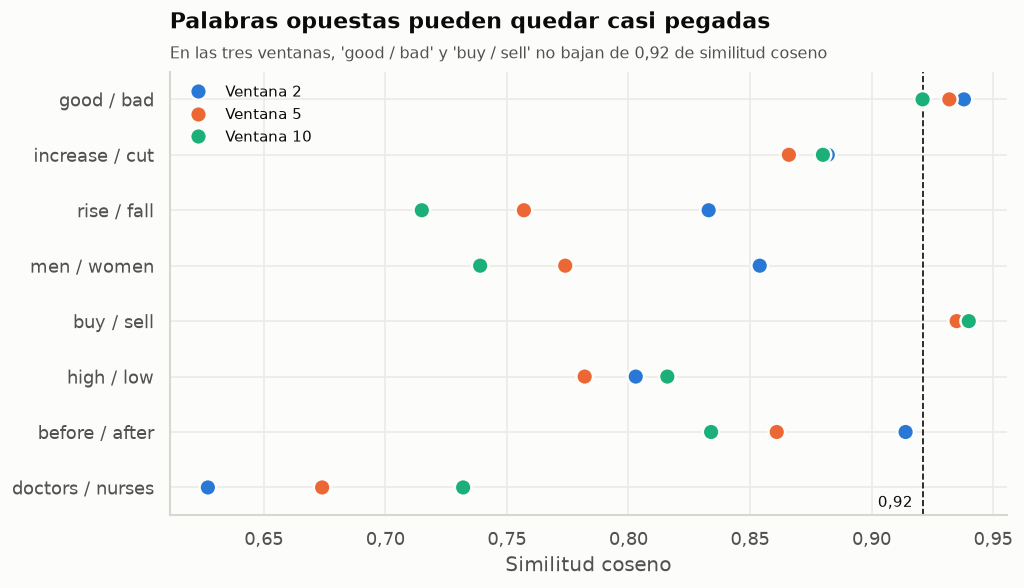

In [30]:
cercania = pd.DataFrame(filas).melt(
    id_vars="Par",
    value_vars=[f"Ventana {v}" for v in VENTANAS],
    var_name="Modelo",
    value_name="Similitud",
)
buenos = cercania[cercania["Par"].isin(["good / bad", "buy / sell"])]["Similitud"].min()

fig, ax = plt.subplots(figsize=(9, 4.8))
sns.stripplot(
    cercania, y="Par", x="Similitud", hue="Modelo",
    palette={"Ventana 2": BLUE, "Ventana 5": ORANGE, "Ventana 10": AQUA},
    size=10, jitter=False, linewidth=1.5, edgecolor=SURFACE, ax=ax,
)
ax.axvline(buenos, color=INK, lw=1, ls="--")
ax.text(buenos - 0.004, 7.35, f"{es(buenos, 2)}", ha="right", fontsize=9)
titular(ax, "Palabras opuestas pueden quedar casi pegadas", f"En las tres ventanas, 'good / bad' y 'buy / sell' no bajan de {es(buenos, 2)} de similitud coseno")
ax.set(xlabel="Similitud coseno", ylabel=None)
ax.grid(axis="y", color="#ecebe6", visible=True)
ax.legend(loc="upper left", fontsize=9, title=None)
ticks_es(ax.xaxis, 2)
plt.show()

### Análisis crítico

La cercanía entre vectores solo dice que dos palabras se usaron en contextos parecidos dentro de estas 1.000 noticias.

- **No es sinonimia.** `good`/`bad` y `buy`/`sell` quedan por encima de 0,92 en las tres ventanas. `government` y `bma` están a 0,85 con ventana 5, y son las dos partes de una disputa salarial.
- **No es verdad.** `tesla` queda a 0,82 de `billionaire`, y Tesla es una empresa. El modelo aprendió que la cobertura los pone juntos, no un hecho sobre Tesla. Los vecinos de `musk` incluyen a `trump` por lo mismo.
- **Refleja lo que se cubrió.** Musk aparece en 123 de las 1.000 noticias, y 44 de las 75 noticias con `doctors` también mencionan `strike`. Otro corpus daría otros vecinos, sin que el mundo hubiera cambiado.
- **La frecuencia limita lo que se puede decir.** `immigration` (21 apariciones) tiene vecinos como `sport`, `aj` y `f`. Incluso `women` (238) trae `rabbits`.
- **La similitud no es una probabilidad.** Los primeros vecinos de `market` llegan a 0,93 o más aunque mezclan `grid` o `longevity`. Un valor alto no garantiza una relación con sentido.
- **Cada palabra tiene un solo vector.** Todos los usos de `market` quedan promediados. Además, las oraciones tienen 22 tokens en promedio, así que la ventana 10 ya roza el límite de la oración.

### Un vector por palabra: el puente hacia Transformers

**Hipótesis:** una palabra con varios sentidos debería quedar a mitad de camino entre ellos, porque Word2Vec le da un solo vector. Lo pruebo con `bank`, que en este corpus tiene sentidos fáciles de identificar por la palabra vecina: finanzas (`central bank`, `bank account`), banco de alimentos (`food bank`) y día festivo (`bank holiday`). También aparece como nombre propio, en `Spring Bank` y `Dogger Bank`; esas apariciones no las etiqueto.

'bank': 109 apariciones, 66 con un sentido claro por la palabra vecina


,Apariciones
Sentido,
Finanzas,45
Banco de alimentos,11
Día festivo,10


,Sentido,Documento,Contexto
9,Banco de alimentos,124,the help of a food bank we can't even live off
10,Banco de alimentos,124,jocelyn lantrip from the food bank of northern nevada which supplies
0,Día festivo,0,meet union representatives over the bank holiday weekend to try to
16,Día festivo,183,have built up over the bank holiday weekend this threatens the
1,Finanzas,18,by analysts though with deutsche bank saying driverless cars face technological
2,Finanzas,62,the spanish flu the world bank estimates that there could be


Sin etiquetar, también aparecen: ['ferensway jameson street and spring bank areas on saturday andrew stewart', "will be connected to dogger bank the world's largest offshore wind", 'on the floor using a bank of screens just outside the']
Vecinos del vector de 'bank': ['flooding', 'steam', 'meme', 'air', 'computer', "country's", 'berlin', 'videos']


,Palabra,Sentido,Similitud,Rango entre los vecinos
0,central,Finanzas,0.933,300
1,account,Finanzas,0.831,4425
2,investment,Finanzas,0.903,1331
3,food,Banco de alimentos,0.824,4654
4,holiday,Día festivo,0.935,256


Vector de 'bank' frente al contexto de Banco de alimentos: 0.907
Vector de 'bank' frente al contexto de Día festivo: 0.844
Vector de 'bank' frente al contexto de Finanzas: 0.901
Contexto de Banco de alimentos frente al de Día festivo: 0.955
Contexto de Banco de alimentos frente al de Finanzas: 0.978
Contexto de Día festivo frente al de Finanzas: 0.951
Promediando el contexto, sin la palabra vecina: acierta 45.5%; responder siempre el sentido mayoritario: 68.2%


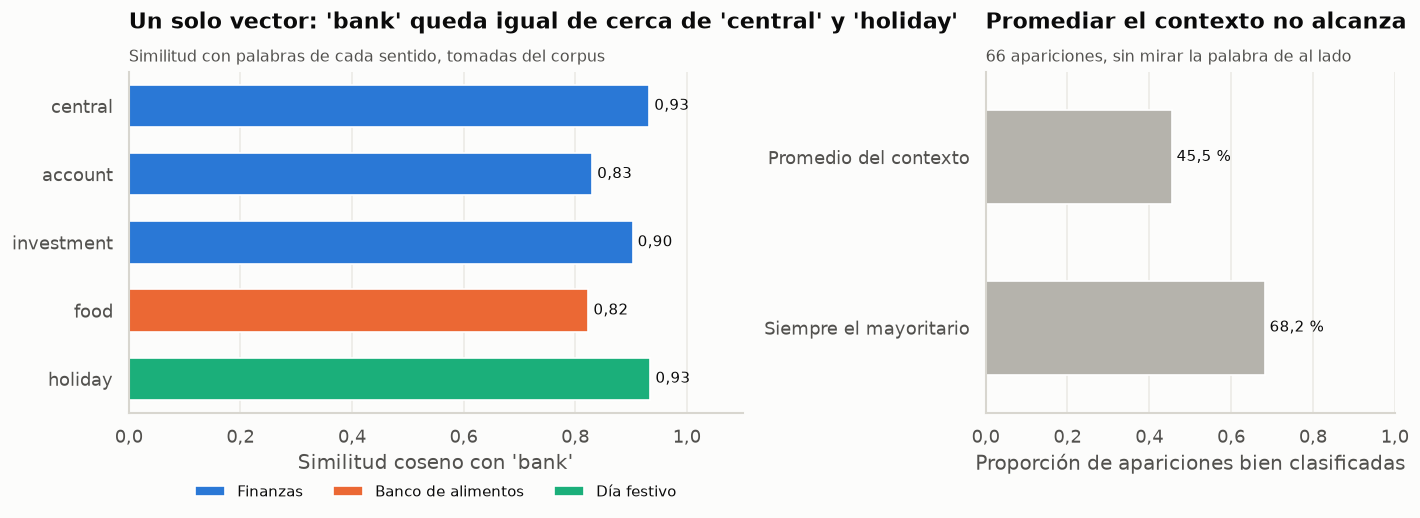

In [31]:
POLISEMICA = "bank"
FINANZAS = {"central", "investment", "world", "deutsche", "swiss", "your", "seng", "triodos", "development"}


def sentido_bank(izquierda, derecha):
    if izquierda == "food":
        return "Banco de alimentos"
    if derecha == "holiday":
        return "Día festivo"
    if izquierda in FINANZAS or derecha in {"account", "accounts", "transfers"}:
        return "Finanzas"
    return None


apariciones = []
for doc, pos in INDICE[POLISEMICA]:
    tokens = df.at[doc, "tokens"]
    izquierda = tokens[pos - 1] if pos else ""
    derecha = tokens[pos + 1] if pos + 1 < len(tokens) else ""
    apariciones.append({
        "Sentido": sentido_bank(izquierda, derecha),
        "Documento": doc,
        "Contexto": " ".join(tokens[max(0, pos - 5):pos + 6]),
        "Posición": pos,
    })
apariciones = pd.DataFrame(apariciones)
etiquetadas = apariciones.dropna(subset="Sentido").copy()
print(f"'{POLISEMICA}': {len(apariciones)} apariciones, {len(etiquetadas)} con un sentido claro por la palabra vecina")
display(etiquetadas["Sentido"].value_counts().to_frame("Apariciones"))
display(etiquetadas.groupby("Sentido").head(2)[["Sentido", "Documento", "Contexto"]].sort_values("Sentido"))
print("Sin etiquetar, también aparecen:", list(apariciones[apariciones["Sentido"].isna()]["Contexto"].iloc[[2, 6, 21]]))

print("Vecinos del vector de 'bank':", [p for p, _ in modelo_5.wv.most_similar(POLISEMICA, topn=8)])
PALABRAS_SENTIDO = {"central": "Finanzas", "account": "Finanzas", "investment": "Finanzas", "food": "Banco de alimentos", "holiday": "Día festivo"}
similitudes_sentido = pd.DataFrame([
    {"Palabra": p, "Sentido": s, "Similitud": float(modelo_5.wv.similarity(POLISEMICA, p)), "Rango entre los vecinos": modelo_5.wv.rank(POLISEMICA, p)}
    for p, s in PALABRAS_SENTIDO.items()
])
display(similitudes_sentido.round(3))


def contexto_lejano(doc, pos, hueco=1, ventana=8):
    tokens = df.at[doc, "tokens"]
    contexto = [
        t for i, t in enumerate(tokens[max(0, pos - ventana):pos + ventana + 1], max(0, pos - ventana))
        if abs(i - pos) > hueco and t in modelo_5.wv and t not in STOP and t != POLISEMICA
    ]
    return np.mean([modelo_5.wv[t] for t in contexto], axis=0) if contexto else None


etiquetadas["Vector"] = [contexto_lejano(d, p) for d, p in zip(etiquetadas["Documento"], etiquetadas["Posición"])]
etiquetadas = etiquetadas.dropna(subset="Vector").reset_index(drop=True)
centroides = {s: np.mean(g["Vector"].tolist(), axis=0) for s, g in etiquetadas.groupby("Sentido")}
vector_estatico = modelo_5.wv[POLISEMICA].reshape(1, -1)
for sentido, centroide in centroides.items():
    print(f"Vector de 'bank' frente al contexto de {sentido}: {cosine_similarity(vector_estatico, centroide.reshape(1, -1))[0, 0]:.3f}")
for a, b in combinations(centroides, 2):
    print(f"Contexto de {a} frente al de {b}: {cosine_similarity(centroides[a].reshape(1, -1), centroides[b].reshape(1, -1))[0, 0]:.3f}")

aciertos = 0
for i, fila in etiquetadas.iterrows():
    resto = etiquetadas.drop(index=i)
    medias = {s: np.mean(g["Vector"].tolist(), axis=0) for s, g in resto.groupby("Sentido")}
    similitudes = {s: cosine_similarity(fila["Vector"].reshape(1, -1), v.reshape(1, -1))[0, 0] for s, v in medias.items()}
    aciertos += max(similitudes, key=similitudes.get) == fila["Sentido"]
acierto_contexto = aciertos / len(etiquetadas)
acierto_mayoria = etiquetadas["Sentido"].value_counts(normalize=True).iloc[0]
print(f"Promediando el contexto, sin la palabra vecina: acierta {acierto_contexto:.1%}; responder siempre el sentido mayoritario: {acierto_mayoria:.1%}")

colores_sentido = {"Finanzas": BLUE, "Banco de alimentos": ORANGE, "Día festivo": AQUA}
fig, (izq, der) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})
sns.barplot(similitudes_sentido, y="Palabra", x="Similitud", hue="Sentido", palette=colores_sentido, dodge=False, width=0.62, saturation=1, ax=izq)
for pos, valor in enumerate(similitudes_sentido["Similitud"]):
    izq.text(valor, pos, f" {es(valor, 2)}", va="center", fontsize=9)
izq.set(xlim=(0, 1.1), ylabel=None, xlabel="Similitud coseno con 'bank'")
izq.grid(axis="y", visible=False)
izq.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncols=3, fontsize=9, title=None)
ticks_es(izq.xaxis, 1)
titular(izq, "Un solo vector: 'bank' queda igual de cerca de 'central' y 'holiday'", "Similitud con palabras de cada sentido, tomadas del corpus")
resumen_acierto = pd.DataFrame({"Método": ["Promedio del contexto", "Siempre el mayoritario"], "Acierto": [acierto_contexto, acierto_mayoria]})
sns.barplot(resumen_acierto, y="Método", x="Acierto", color=GRAY, width=0.55, saturation=1, ax=der)
for pos, valor in enumerate(resumen_acierto["Acierto"]):
    der.text(valor, pos, f" {es(valor * 100, 1)} %", va="center", fontsize=9)
der.set(xlim=(0, 1), ylabel=None, xlabel="Proporción de apariciones bien clasificadas")
der.grid(axis="y", visible=False)
ticks_es(der.xaxis, 1)
titular(der, "Promediar el contexto no alcanza", f"{len(etiquetadas)} apariciones, sin mirar la palabra de al lado")
plt.tight_layout()
plt.show()

**Hallazgo:** se sostiene solo en parte. Ninguno de los primeros vecinos de `bank` (`flooding`, `steam`, `meme`, `air`, `computer`) corresponde a un sentido, y el vector queda igual de cerca de `central` que de `holiday` (0,93 en los dos). También queda a 0,90 del contexto financiero y a 0,91 del de `food bank`, aunque el sentido financiero aparece cuatro veces más. Eso se parece a quedar en el medio, pero la evidencia es débil: esos contextos promediados se parecen mucho entre sí (0,95 a 0,98).

La segunda prueba fue más clara. Promediando el contexto, sin mirar la palabra de al lado, acierto el sentido el 45,5 % de las veces, menos que el 68,2 % de responder siempre el mayoritario. Con `food` o `holiday` justo al lado, en cambio, el sentido es evidente. Esa comparación tiene trampa, porque etiqueté así los sentidos, pero muestra el punto: no todas las palabras del contexto pesan igual.

Ahí es donde entra self-attention. En vez de un vector fijo por palabra y un promedio plano, cada aparición de `bank` construye su representación ponderando las otras palabras de la oración, y esos pesos se aprenden. Aquí no entrené ningún Transformer, así que esto no lo mido: es la limitación que estos resultados dejan abierta.

### <a id="resumen-rep"></a>Resumen de representaciones

**Hipótesis:** BoW y TF-IDF deberían ser más rápidas y más dispersas, y Word2Vec debería dar más similitud al par O1/O2 de lo que da a pares al azar. Vuelvo a entrenar los modelos solo para medir el tiempo; con la misma semilla dan los mismos vectores. Los tiempos cambian un poco en cada ejecución.

In [32]:
%%capture --no-stdout --no-display
def medir(funcion):
    inicio = time.perf_counter()
    resultado = funcion()
    return resultado, time.perf_counter() - inicio


matriz_bow, tiempo_bow = medir(lambda: matriz_conteos(df["tokens"]))
_, tiempo_tfidf = medir(lambda: TfidfTransformer().fit_transform(matriz_bow))
tiempos_w2v = {v: medir(lambda: entrenar_word2vec(v))[1] for v in VENTANAS}

oraciones_base_disperso = matriz_conteos(oraciones_base)
azar_bow = coseno_azar_disperso(oraciones_base_disperso)
azar_tfidf = coseno_azar_disperso(TRANSFORMADOR_TFIDF.transform(oraciones_base_disperso))
par_conteos = matriz_conteos(tokens_mapa[:2])
filas_resumen = [
    {"Representación": "Bag of Words", "Unidad": "Noticia", "Tiempo (s)": tiempo_bow, "Vocabulario": BOW_CORPUS.shape[1], "Esparsidad %": esparsidad_bow * 100,
     "Coseno O1/O2": cosine_similarity(par_conteos)[0, 1], "Coseno medio al azar": azar_bow.mean()},
    {"Representación": "TF-IDF", "Unidad": "Noticia", "Tiempo (s)": tiempo_tfidf, "Vocabulario": TFIDF_CORPUS.shape[1], "Esparsidad %": (1 - TFIDF_CORPUS.nnz / np.prod(TFIDF_CORPUS.shape)) * 100,
     "Coseno O1/O2": cosine_similarity(TRANSFORMADOR_TFIDF.transform(par_conteos))[0, 1], "Coseno medio al azar": azar_tfidf.mean()},
]
for v, modelo in MODELOS.items():
    par = cosine_similarity(np.array([vector_oracion(t, modelo) for t in tokens_mapa[:2]]))[0, 1]
    filas_resumen.append({
        "Representación": f"Word2Vec, ventana {v}", "Unidad": "Palabra", "Tiempo (s)": tiempos_w2v[v], "Vocabulario": len(modelo.wv),
        "Esparsidad %": np.mean(modelo.wv.vectors == 0) * 100, "Coseno O1/O2": par, "Coseno medio al azar": coseno_azar_w2v(modelo).mean(),
    })
resumen = pd.DataFrame(filas_resumen).set_index("Representación")
display(resumen.round({"Tiempo (s)": 2, "Esparsidad %": 2, "Coseno O1/O2": 3, "Coseno medio al azar": 3}))

,Unidad,Tiempo (s),Vocabulario,Esparsidad %,Coseno O1/O2,Coseno medio al azar
Representación,,,,,,
Bag of Words,Noticia,0.09,25616,99.02,0.000,0.080
TF-IDF,Noticia,0.00,25616,99.02,0.000,0.013
"Word2Vec, ventana 2",Palabra,0.99,7924,0.00,0.816,0.720
"Word2Vec, ventana 5",Palabra,1.33,7924,0.00,0.786,0.650
"Word2Vec, ventana 10",Palabra,1.30,7924,0.00,0.802,0.589


**Hallazgo:** BoW y TF-IDF se calculan más rápido que entrenar Word2Vec, pero son casi 99 % ceros y dan 0 en el par O1/O2, menos que su propio promedio al azar. Word2Vec es denso y le da al par más similitud que a dos oraciones al azar: 0,786 frente a 0,650 con ventana 5. A cambio, solo cubre 7.924 palabras por `min_count=5`, y esa diferencia viene de un solo par, así que no la tomo como una medida general de calidad. Tampoco comparan exactamente lo mismo: BoW y TF-IDF representan noticias, y Word2Vec, palabras.

### <a id="conclusion"></a>Conclusión

Bag of Words representa cada noticia como conteos de palabras: usa solo qué aparece y cuánto, y se lee fácil.  
Su limitación es que pierde el orden: `The student corrects the teacher` y su inversa dan el mismo vector.  
Word2Vec representa cada palabra con un vector denso aprendido de sus vecinas en una ventana, así que capta parecidos de uso como `doctors` y `consultants`.  
Su limitación es que cercanía significa contextos compartidos, no significado ni verdad: `good` queda a 0,94 de `bad` y `tesla` a 0,82 de `billionaire`.  
Además depende de la frecuencia: con menos de 20 apariciones, los vecinos casi no se repiten ni cambiando solo la semilla.